## K-Means, Hierarchical, and Gaussian Mixture Models

## Nombre: Leny Tacuri

## Repositorio:

*<small>Last updated: 2026-10-01 18:06:24 UTC | Student Version (No Solutions)</small>*

# Clustering: K-Means, Hierarchical, and Gaussian Mixture Models [SOLUTIONS]

**Course**: Machine Learning Labs
**Lab**: 08 — Clustering

---

## Table of Contents

0. [Setup and Configuration](#0)
1. [Introduction to Clustering](#1)
2. [Dataset 1: Online Retail & RFM Feature Engineering](#2)
3. [K-Means Clustering](#3)
4. [Hierarchical Clustering](#4)
5. [Gaussian Mixture Models](#5)
6. [Comparative Analysis on Online Retail](#6)
7. [Dataset 2: HAR & External Evaluation (ARI / NMI)](#7)
8. [Real-World Considerations](#8)
9. [Final Challenges](#9)

---

**Estimated Time**: 3–4 hours
**Prerequisites**: Unsupervised learning basics, scikit-learn, NumPy, Pandas

**Note**: This is the SOLUTIONS version containing all exercise answers.

## 🚚 Deliverables

**Don't forget to duplicate this notebook to be able to edit: File -> Save a copy in Drive**

In this lab, you do not need to write a report in a separate document. Please complete all required
activities within this Google Colab notebook. Remember that a notebook allows you to enter text
elements similarly to a document processor. Once the proposed activities are completed, you must
submit the following on the platform:

1. A PDF file generated in Google Colab from the menu "File" -> "Print".

2. The public Google Colab link. To do so, go to the share button and change the sharing settings
   to "Anyone with the link".

## 📔 Resolution

After the deadline, you will find the resolution at the following Notion link:

https://app.notion.com/p/R-Clustering-46264f3ff1004fc8ad39badb0ed7c86f?source=copy_link

Remember that there are several ways to solve the proposed activities in the labs.
Use the provided resolution as a reference. If the resolution link is not public,
request access at the same Notion link.

## Section 0: Setup and Configuration <a id='0'></a>

In [1]:
try:
    import google.colab
    IN_COLAB = True
    import subprocess
    subprocess.run(["pip", "install", "-q", "openpyxl"], check=True)
except ImportError:
    IN_COLAB = False

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.datasets import fetch_openml, load_sample_image
from sklearn.metrics import (
    silhouette_score, silhouette_samples,
    davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score, normalized_mutual_info_score,
)
from sklearn.utils import shuffle

import sklearn
warnings.filterwarnings('ignore')
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

NumPy 2.5.4 | Pandas 3.0.6 | scikit-learn 1.9.1


In [4]:
# ── Global configuration ─────────────────────────────────────────────────────
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

ONLINE_RETAIL_URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases"
    "/00352/Online%20Retail.xlsx"
)

plt.rcParams['figure.dpi'] = 100
sns.set_theme(style='whitegrid', palette='tab10')

## Section 1: Introduction to Clustering <a id='1'></a>

**Clustering** is an unsupervised learning task: given unlabeled data, discover
groups of similar observations — without any prior knowledge of what those groups
should be.

| Property | Hard assignment | Soft assignment |
|---|---|---|
| Each point belongs to | exactly one cluster | all clusters (with probabilities) |
| Algorithms | K-Means, Hierarchical | Gaussian Mixture Models |
| Output | integer label | probability vector |

### Real-world applications

- **Customer segmentation**: group buyers by purchasing behaviour (Online Retail)
- **Activity detection**: identify motion patterns from smartphone sensors (HAR)
- **Document grouping**: cluster news articles by topic

### This lab

We use **two datasets** with distinct goals:

1. **Online Retail (UCI)** — no ground-truth labels.
   We engineer RFM features and compare K-Means, Hierarchical, and GMM using
   *internal* metrics (silhouette, Davies-Bouldin, Calinski-Harabasz).

2. **Human Activity Recognition (HAR)** — 6 known activity labels.
   We measure clustering quality using *external* metrics (ARI, NMI) and
   compare them to what internal metrics alone would suggest.

## Section 2: Dataset 1 — Online Retail & RFM Feature Engineering <a id='2'></a>

The [Online Retail dataset (UCI)](https://archive.ics.uci.edu/ml/datasets/Online+Retail)
contains ~541 k invoice records from a UK-based online retailer (Dec 2010 – Dec 2011).
Each row is one product line within a transaction (invoice number, stock code,
quantity, unit price, timestamp, customer ID, country).

**The problem**: this is a *transaction-level* log, but we want to cluster
*customers*. Clustering raw transactions would group purchases, not people — so
before any model touches the data, we must aggregate the log into one row per
customer. The standard, battle-tested way to summarise customer behaviour for
segmentation is the **RFM** framework.

### What is RFM?

RFM distils a customer's entire purchase history into three interpretable
behavioural signals. Each is computed by grouping all of a customer's transactions
and applying a single aggregation:

| Feature | Question it answers | How we compute it | Business meaning |
|---|---|---|---|
| **R**ecency | *How long since the customer last bought?* | days between the customer's most recent invoice and a fixed reference date | low Recency → recently active; high Recency → at risk of churn |
| **F**requency | *How often does the customer buy?* | count of **distinct invoices** per customer | high Frequency → engaged, loyal, habitual buyer |
| **M**onetary | *How much does the customer spend?* | sum of `Quantity × UnitPrice` across all their lines | high Monetary → high-value customer worth retaining |

The classic marketing intuition: the *best* customers bought **recently**, buy
**often**, and **spend** a lot. RFM turns that intuition into three numbers that
a clustering algorithm can act on.

### Modelling decisions baked into the features

A few choices matter and are easy to get wrong:

- **Reference date for Recency.** "Today" is meaningless for a historical dataset,
  so we anchor Recency to the day *after* the last transaction in the data
  (`max(InvoiceDate) + 1 day`). This guarantees every customer has a Recency of at
  least 1 day and makes the feature reproducible.
- **Frequency = distinct invoices, not line items.** A single basket of 20 products
  is *one* purchase event, not 20. Counting unique `InvoiceNo` values captures
  *shopping trips*; counting rows would just reward large baskets.
- **Monetary uses revenue per line.** We pre-computed `TotalPrice = Quantity ×
  UnitPrice` during cleaning, then sum it per customer to get lifetime spend.

### Why preprocessing is not optional here

RFM features are wildly different in scale and shape, which breaks distance-based
clustering if left untreated:

- **Different units and ranges.** Recency is in *days* (1–374), Frequency is a
  *count* (1–209), Monetary is in *pounds* (£3 to £280 k). Without
  standardisation, Monetary's magnitude would dominate every Euclidean distance and
  K-Means would essentially cluster on spend alone.
- **Heavy right skew.** A small number of "whale" customers buy enormously more
  than the median, producing long right tails (especially in Frequency and
  Monetary). Skew pulls cluster centroids toward outliers. We apply a
  **`log1p` transform** to Frequency and Monetary to compress those tails toward
  symmetry, then verify the effect numerically with a skewness table (Recency is
  already roughly symmetric, so we leave it untransformed).
- **Order of operations.** Aggregate → log-transform the skewed features →
  **standardise** (zero mean, unit variance). Scaling must come *last* so every
  feature contributes comparably to the distance metric.

**Goal of this section**: turn the raw 541 k-row transaction log into a clean,
4 338-customer RFM table that is correctly transformed and scaled — the input on
which we will compare K-Means, Hierarchical, and GMM in the sections that follow.

In [5]:
# Load — try local cache first, fall back to URL
local_path = os.path.join("assets", "Online_Retail.xlsx")
if os.path.exists(local_path):
    df_raw = pd.read_excel(local_path, engine="openpyxl")
else:
    print("Downloading Online Retail dataset (~23 MB)…")
    df_raw = pd.read_excel(ONLINE_RETAIL_URL, engine="openpyxl")
    os.makedirs("assets", exist_ok=True)
    df_raw.to_excel(local_path, index=False)
    print("Saved to assets/Online_Retail.xlsx for future runs.")

print(f"Raw shape: {df_raw.shape}")
df_raw.head()

Saved to assets/Online_Retail.xlsx for future runs.
Raw shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
# Basic EDA
print(f"Date range: {df_raw['InvoiceDate'].min()} → {df_raw['InvoiceDate'].max()}")
print(f"Unique customers: {df_raw['CustomerID'].nunique():,}")
print(f"Unique products:  {df_raw['StockCode'].nunique():,}")
print(f"\nMissing values:\n{df_raw.isnull().sum()}")

Date range: 2010-12-01 08:26:00 → 2011-12-09 12:50:00
Unique customers: 4,372
Unique products:  4,070

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [7]:
# Clean: remove returns, missing customers, zero/negative prices
df = df_raw.dropna(subset=['CustomerID']).copy()
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
df['CustomerID'] = df['CustomerID'].astype(int)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

print(f"After cleaning: {len(df):,} rows | {df['CustomerID'].nunique():,} customers")

After cleaning: 397,884 rows | 4,338 customers


In [8]:
# RFM feature engineering
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalPrice', 'sum'),
).reset_index()

print(f"RFM table shape: {rfm.shape}")
rfm[['Recency', 'Frequency', 'Monetary']].describe().round(2)

RFM table shape: (4338, 4)


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2054.27
std,100.01,7.70,8989.23
min,1.00,1.00,3.75
25%,18.00,1.00,307.41
50%,51.00,2.00,674.48
75%,142.00,5.00,1661.74
max,374.00,209.00,280206.02


In [9]:
# Log-transform Frequency and Monetary to reduce right skew.
# Recency is already roughly symmetric, so we leave it untransformed.
log_features = ['Frequency', 'Monetary']

rfm_log = rfm[['Recency', 'Frequency', 'Monetary']].copy()
rfm_log[log_features] = np.log1p(rfm_log[log_features])

# Quantify skewness to justify the transform (rule of thumb: |skew| > 1 = strong,
# 0.5–1 = moderate, < 0.5 = approximately symmetric)
skewness = pd.DataFrame({
    'Skew (raw)':         rfm[['Recency', 'Frequency', 'Monetary']].skew(),
    'Skew (transformed)': rfm_log[['Recency', 'Frequency', 'Monetary']].skew(),
}).round(2)
print("Skewness before vs after log transform:")
print(skewness.to_string())

# Standardise — mandatory before any distance-based algorithm
scaler = StandardScaler()
X = scaler.fit_transform(rfm_log)
print(f"\nScaled feature matrix: {X.shape}  mean≈{X.mean():.2f}  std≈{X.std():.2f}")

Skewness before vs after log transform:
           Skew (raw)  Skew (transformed)
Recency          1.25                1.25
Frequency       12.07                1.21
Monetary        19.32                0.39

Scaled feature matrix: (4338, 3)  mean≈0.00  std≈1.00


### Exercise 2.1 — RFM Distributions (Basic)

Plot the raw and log-transformed distributions for all three RFM features in a
2 × 3 grid (top row = raw, bottom row = transformed).

**What to observe**: Does the log transform bring the distributions closer to
symmetric? Which feature benefits the most?

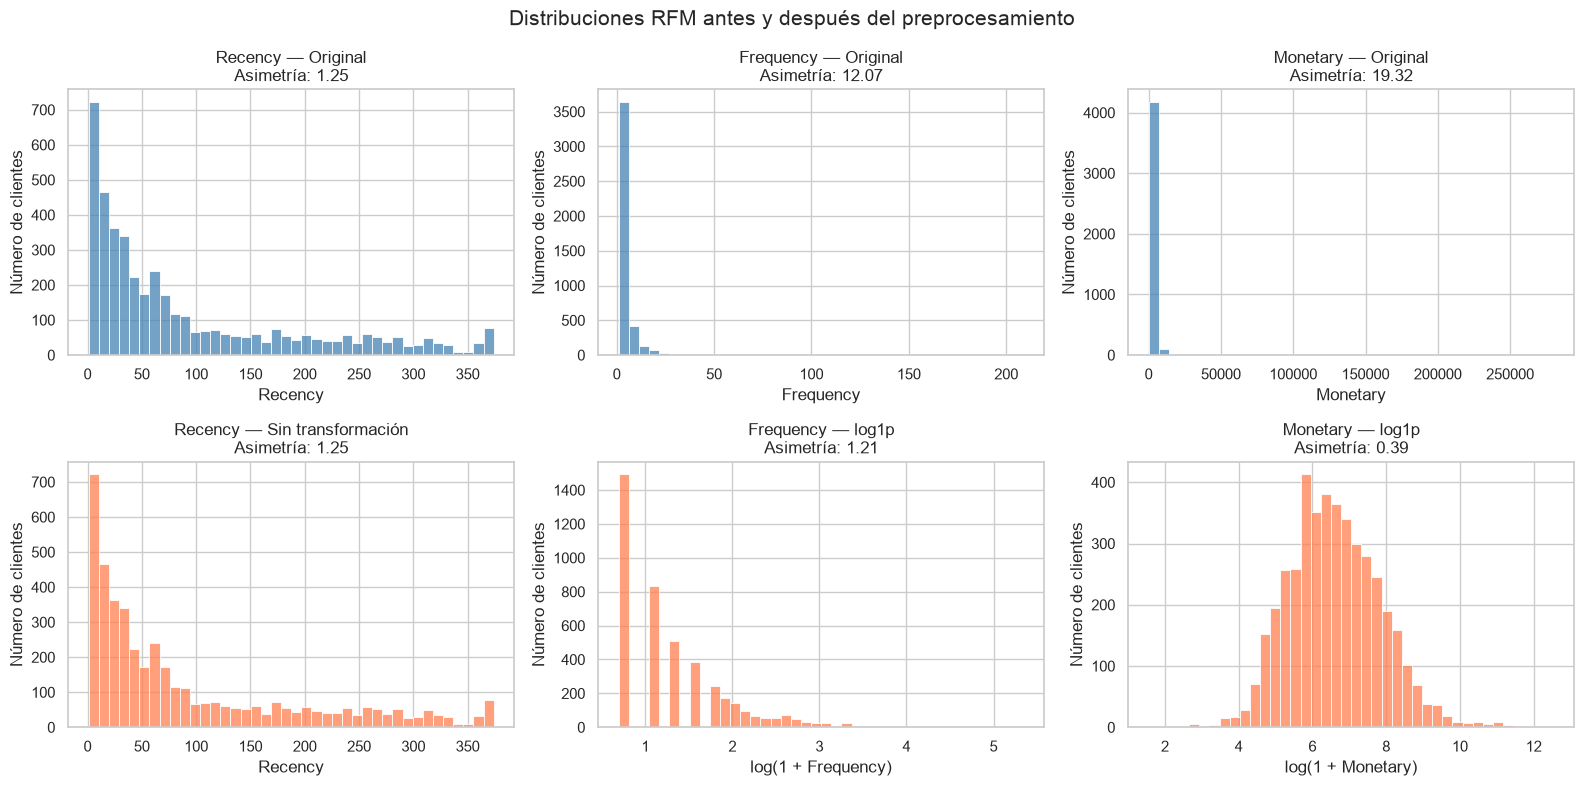

In [10]:
features = ['Recency', 'Frequency', 'Monetary']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for j, feature in enumerate(features):
    # Distribución original
    sns.histplot(rfm[feature], bins=40, ax=axes[0, j],
                 color='steelblue')
    axes[0, j].set_title(
        f'{feature} — Original\nAsimetría: {rfm[feature].skew():.2f}'
    )

    # Distribución después del preprocesamiento
    sns.histplot(rfm_log[feature], bins=40, ax=axes[1, j],
                 color='coral')
    transformation = 'Sin transformación' if feature == 'Recency' else 'log1p'
    axes[1, j].set_title(
        f'{feature} — {transformation}\n'
        f'Asimetría: {rfm_log[feature].skew():.2f}'
    )
    axes[1, j].set_xlabel(
        feature if feature == 'Recency' else f'log(1 + {feature})'
    )

    for i in range(2):
        axes[i, j].set_ylabel('Número de clientes')

plt.suptitle('Distribuciones RFM antes y después del preprocesamiento',
             fontsize=15)
plt.tight_layout()
plt.show()

## Section 3: K-Means Clustering <a id='3'></a>

### Algorithm recap

**Lloyd's algorithm**:
1. Randomly initialise k centroids (or use K-Means++ for smarter placement)
2. Assign each point to the nearest centroid (hard assignment)
3. Recompute centroids as cluster means
4. Repeat 2–3 until centroids stop moving

**Inertia** (within-cluster sum of squared distances) decreases monotonically
with k — so we use the *elbow* heuristic to pick a sensible k.
**Silhouette score** provides a second opinion: higher is better, range [−1, 1].

### Choosing k: elbow + silhouette

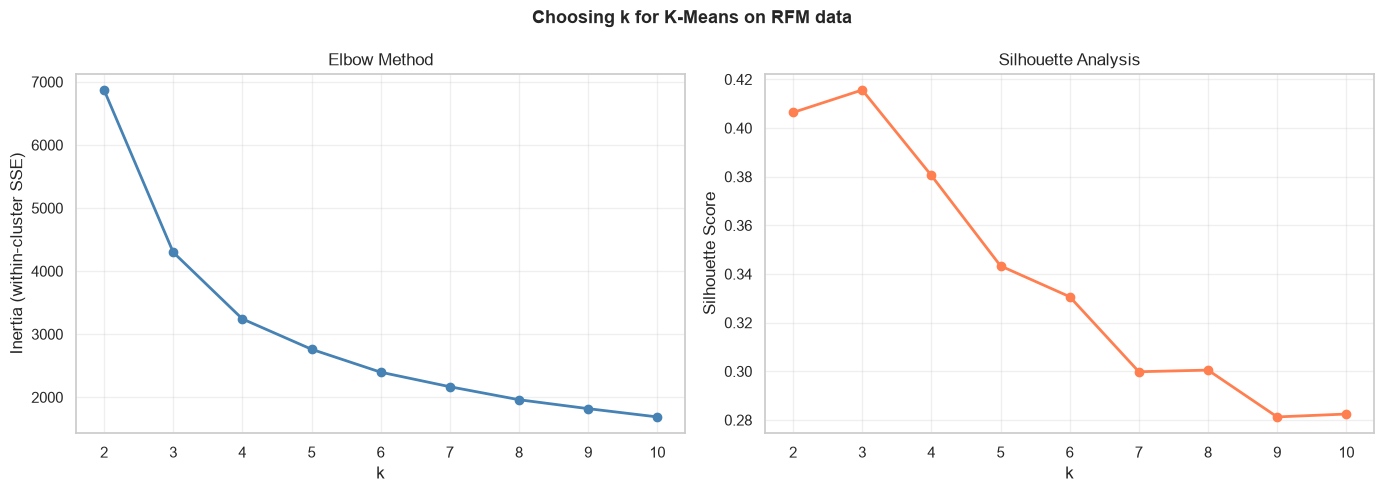

In [11]:
k_range = range(2, 11)
inertias, sil_scores = [], []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, inertias, 'o-', color='steelblue', linewidth=2)
axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia (within-cluster SSE)')
axes[0].set_title('Elbow Method')
axes[0].grid(True, alpha=0.3)

axes[1].plot(k_range, sil_scores, 'o-', color='coral', linewidth=2)
axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Analysis')
axes[1].grid(True, alpha=0.3)

plt.suptitle('Choosing k for K-Means on RFM data', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [12]:
# Fit final model with chosen k
K_BEST = 3  # adjust if your elbow/silhouette suggests a different value

km_final = KMeans(n_clusters=K_BEST, init='k-means++', n_init=10, random_state=RANDOM_STATE)
rfm['Cluster_KM'] = km_final.fit_predict(X)

print(f"Cluster sizes (K-Means, k={K_BEST}):")
print(rfm['Cluster_KM'].value_counts().sort_index().to_string())

Cluster sizes (K-Means, k=3):
Cluster_KM
0    2036
1    1323
2     979


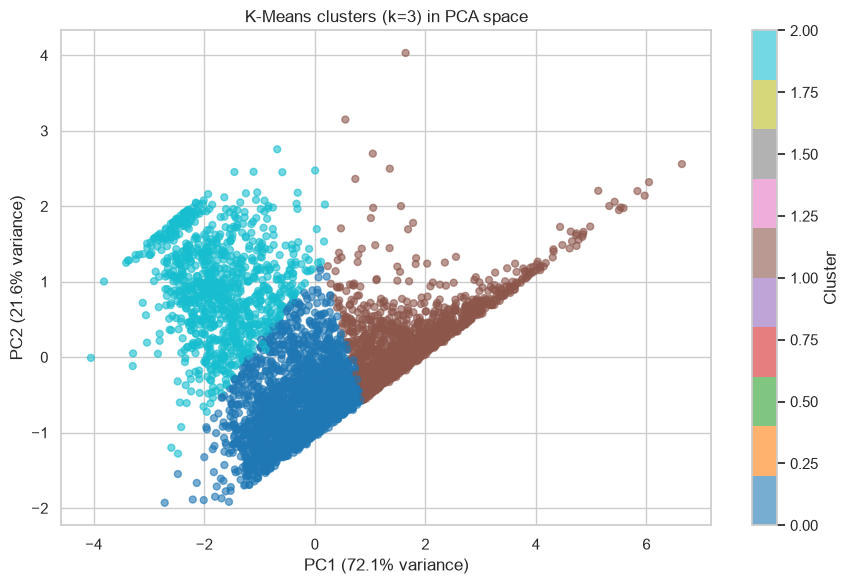

In [13]:
# PCA projection for 2-D visualisation
pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca2.fit_transform(X)
explained = pca2.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(X_pca[:, 0], X_pca[:, 1],
                c=rfm['Cluster_KM'], cmap='tab10', alpha=0.6, s=25)
ax.set_xlabel(f'PC1 ({explained[0]:.1%} variance)')
ax.set_ylabel(f'PC2 ({explained[1]:.1%} variance)')
ax.set_title(f'K-Means clusters (k={K_BEST}) in PCA space')
plt.colorbar(sc, ax=ax, label='Cluster')
plt.tight_layout()
plt.show()

In [14]:
# Cluster profiles — business interpretation
profile = rfm.groupby('Cluster_KM').agg(
    Count=('CustomerID', 'count'),
    Recency_days=('Recency', 'mean'),
    Frequency_orders=('Frequency', 'mean'),
    Monetary_gbp=('Monetary', 'mean'),
).round(1)
profile['% customers'] = (profile['Count'] / len(rfm) * 100).round(1)
profile

,Count,Recency_days,Frequency_orders,Monetary_gbp,% customers
Cluster_KM,,,,,
0,2036,54.9,2.0,615.2,46.9
1,1323,30.1,9.8,5494.3,30.5
2,979,255.3,1.4,398.1,22.6


### Exercise 3.1 — Effect of k (Basic)

Fit K-Means for k ∈ {2, 3, 4, 5, 6, 7} and display each result as a PCA
scatter plot in a 2 × 3 grid. Include the silhouette score in each subplot title.

**What to observe**: At what point do clusters become too fragmented to be
business-meaningful?

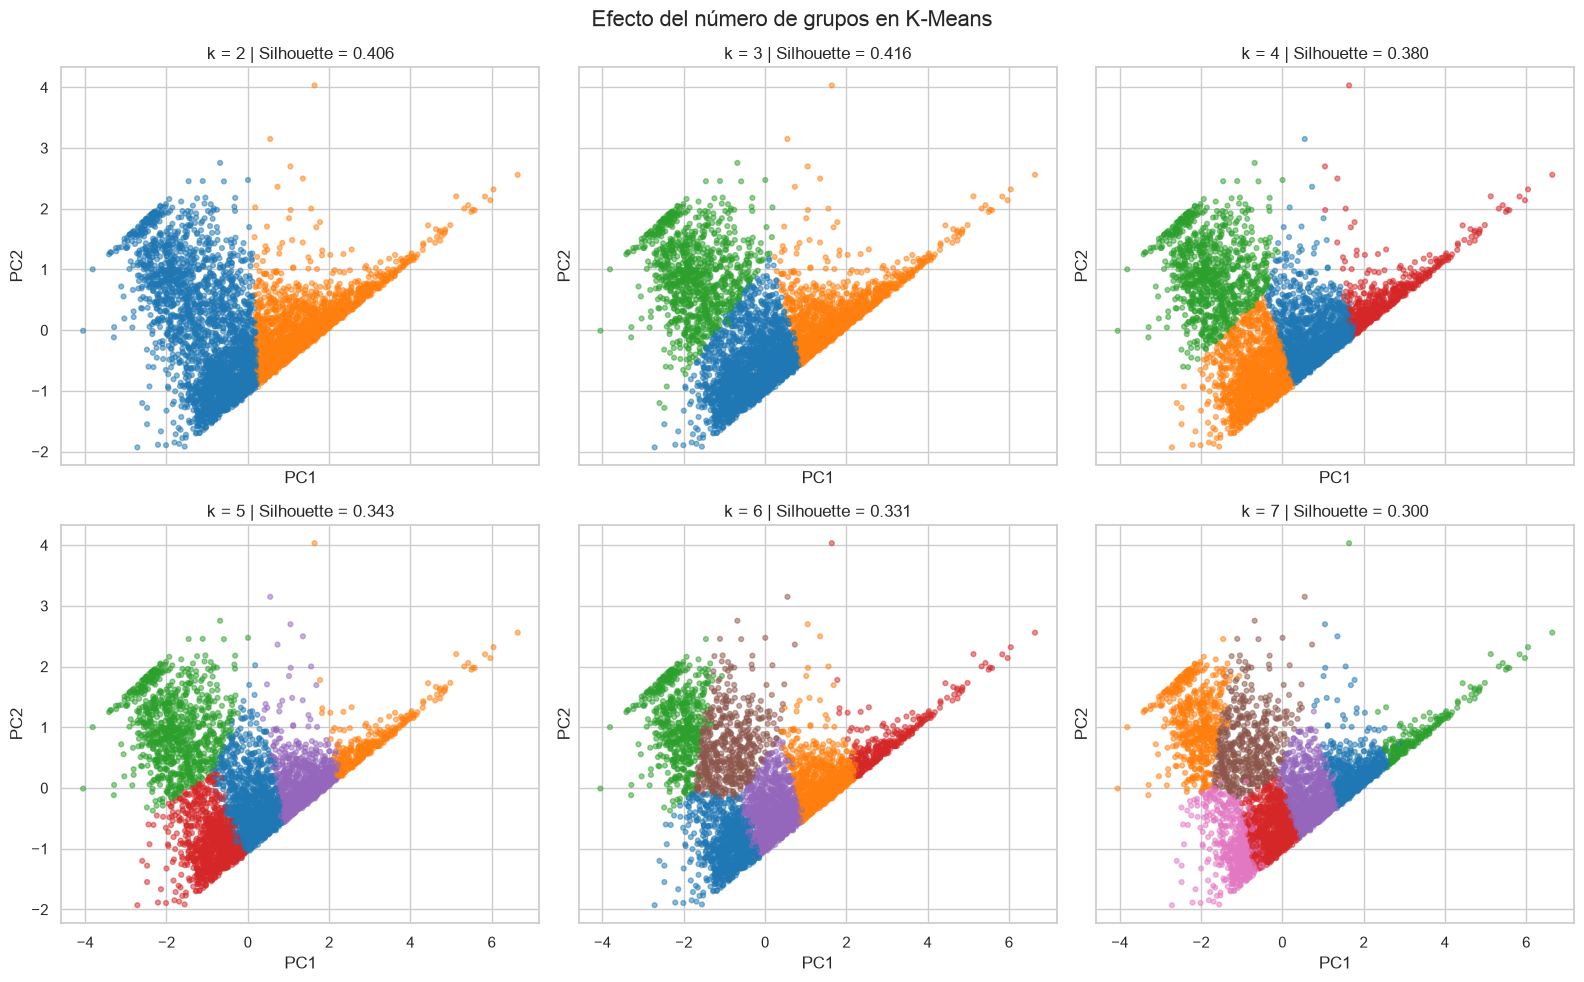

,k,Silhouette,Inercia,Menor grupo,Mayor grupo
0,2,0.406,6872.757,1822,2516
1,3,0.416,4298.645,979,2036
2,4,0.380,3242.055,558,1447
3,5,0.343,2760.928,324,1205
4,6,0.331,2397.223,322,1111
5,7,0.300,2166.672,205,970


Mayor Silhouette entre los valores evaluados: k = 3


In [15]:
fig, axes = plt.subplots(
    2, 3, figsize=(16, 10), sharex=True, sharey=True
)
results_k = []

for ax, k in zip(axes.flat, range(2, 8)):
    model = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        random_state=RANDOM_STATE
    )
    labels = model.fit_predict(X)
    score = silhouette_score(X, labels)

    ax.scatter(
        X_pca[:, 0], X_pca[:, 1],
        c=labels, cmap='tab10', vmin=0, vmax=9,
        s=12, alpha=0.5
    )
    ax.set_title(f'k = {k} | Silhouette = {score:.3f}')
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')

    sizes = np.bincount(labels)
    results_k.append({
        'k': k,
        'Silhouette': score,
        'Inercia': model.inertia_,
        'Menor grupo': sizes.min(),
        'Mayor grupo': sizes.max()
    })

plt.suptitle('Efecto del número de grupos en K-Means', fontsize=16)
plt.tight_layout()
plt.show()

comparison_k = pd.DataFrame(results_k)
display(comparison_k.round(3))

best_k = int(
    comparison_k.loc[comparison_k['Silhouette'].idxmax(), 'k']
)
print(f'Mayor Silhouette entre los valores evaluados: k = {best_k}')

### Exercise 3.2 — Initialisation Strategies (Intermediate)

Run K-Means 10 times using `n_init=1` with both `init='random'` and
`init='k-means++'`. For each trial record the final inertia and number of
iterations. Plot side-by-side boxplots.

**Key question**: Which initialisation is more stable? Which converges faster?

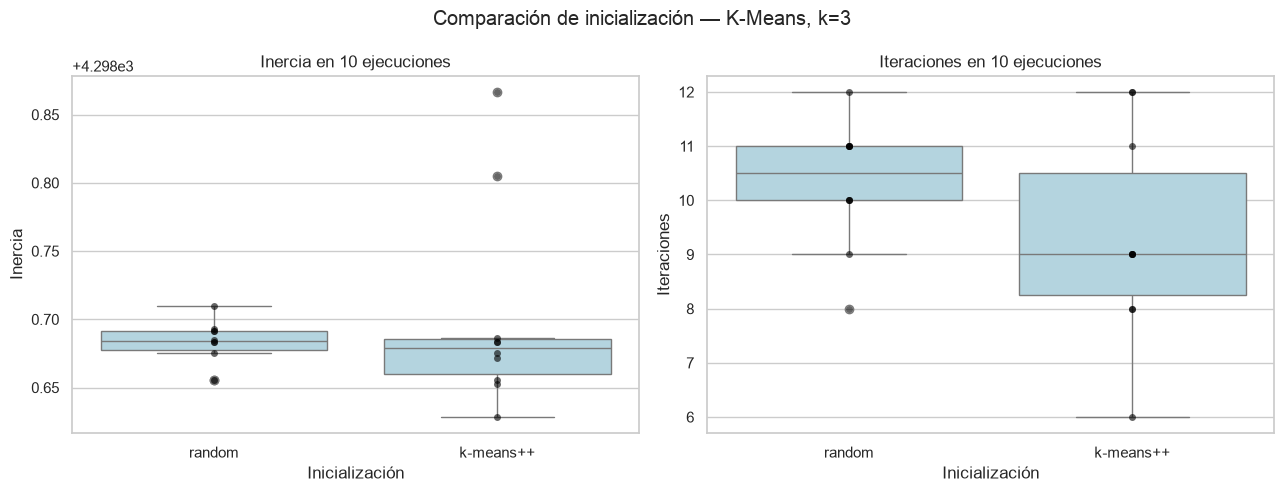

,Inercia_media,Inercia_std,Iteraciones_media,Iteraciones_mediana
Inicialización,,,,
k-means++,4298.701,0.075,9.3,9.0
random,4298.682,0.017,10.3,10.5


In [16]:
init_results = []

for strategy in ['random', 'k-means++']:
    for trial in range(10):
        model = KMeans(
            n_clusters=K_BEST,
            init=strategy,
            n_init=1,
            random_state=RANDOM_STATE + trial
        )
        model.fit(X)

        init_results.append({
            'Inicialización': strategy,
            'Ensayo': trial + 1,
            'Inercia': model.inertia_,
            'Iteraciones': model.n_iter_
        })

df_init = pd.DataFrame(init_results)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, metric in zip(axes, ['Inercia', 'Iteraciones']):
    sns.boxplot(
        data=df_init, x='Inicialización', y=metric,
        ax=ax, color='lightblue'
    )
    sns.stripplot(
        data=df_init, x='Inicialización', y=metric,
        ax=ax, color='black', size=5, jitter=False, alpha=0.6
    )
    ax.set_title(f'{metric} en 10 ejecuciones')

plt.suptitle(f'Comparación de inicialización — K-Means, k={K_BEST}')
plt.tight_layout()
plt.show()

summary_init = df_init.groupby('Inicialización').agg(
    Inercia_media=('Inercia', 'mean'),
    Inercia_std=('Inercia', 'std'),
    Iteraciones_media=('Iteraciones', 'mean'),
    Iteraciones_mediana=('Iteraciones', 'median')
)

display(summary_init.round(3))

## Section 4: Hierarchical Clustering <a id='4'></a>

**Agglomerative** hierarchical clustering starts with each point as its own cluster
and merges the two closest clusters at each step. The merge history is visualised
as a **dendrogram**.

The *linkage criterion* defines "distance between clusters":

| Linkage | Definition | Tendency |
|---|---|---|
| Single | min pairwise distance | chaining, elongated clusters |
| Complete | max pairwise distance | compact, similar-size clusters |
| Average | mean pairwise distance | compromise |
| **Ward** | minimise within-cluster variance | spherical, balanced (default choice) |

**Complexity**: O(n² log n) — we subsample to 400 customers for the dendrogram.

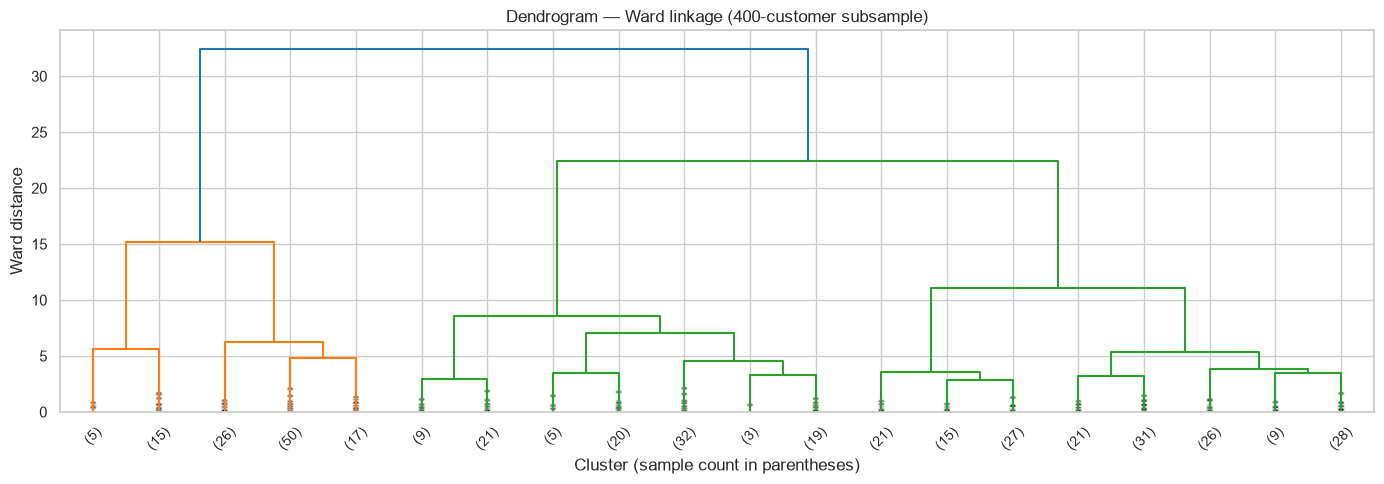

In [17]:
# Dendrogram on a subsample for readability
np.random.seed(RANDOM_STATE)
sub_idx = np.random.choice(len(X), size=min(400, len(X)), replace=False)
X_sub = X[sub_idx]

Z = linkage(X_sub, method='ward')

fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z, ax=ax, truncate_mode='lastp', p=20,
           leaf_rotation=45, leaf_font_size=10, show_contracted=True)
ax.set_title(f'Dendrogram — Ward linkage (400-customer subsample)')
ax.set_xlabel('Cluster (sample count in parentheses)')
ax.set_ylabel('Ward distance')
plt.tight_layout()
plt.show()

In [18]:
# Fit on full dataset and compare to K-Means
agg = AgglomerativeClustering(n_clusters=K_BEST, linkage='ward')
rfm['Cluster_Agg'] = agg.fit_predict(X)

sil_km  = silhouette_score(X, rfm['Cluster_KM'])
sil_agg = silhouette_score(X, rfm['Cluster_Agg'])
print(f"Silhouette — K-Means: {sil_km:.4f}  |  Hierarchical (Ward): {sil_agg:.4f}")
print(f"\nCluster sizes (Hierarchical):")
print(rfm['Cluster_Agg'].value_counts().sort_index().to_string())

Silhouette — K-Means: 0.4156  |  Hierarchical (Ward): 0.3959

Cluster sizes (Hierarchical):
Cluster_Agg
0    1528
1    1937
2     873


### Exercise 4.1 — Linkage Comparison (Intermediate)

Plot dendrograms for Ward, Complete, Average, and Single linkage in a 2 × 2
grid (same 400-customer subsample). Below each dendrogram, cut the tree at
`k = K_BEST` and print the resulting cluster sizes.

**Key question**: Which linkage produces the most balanced clusters?
Why does Single linkage behave differently?

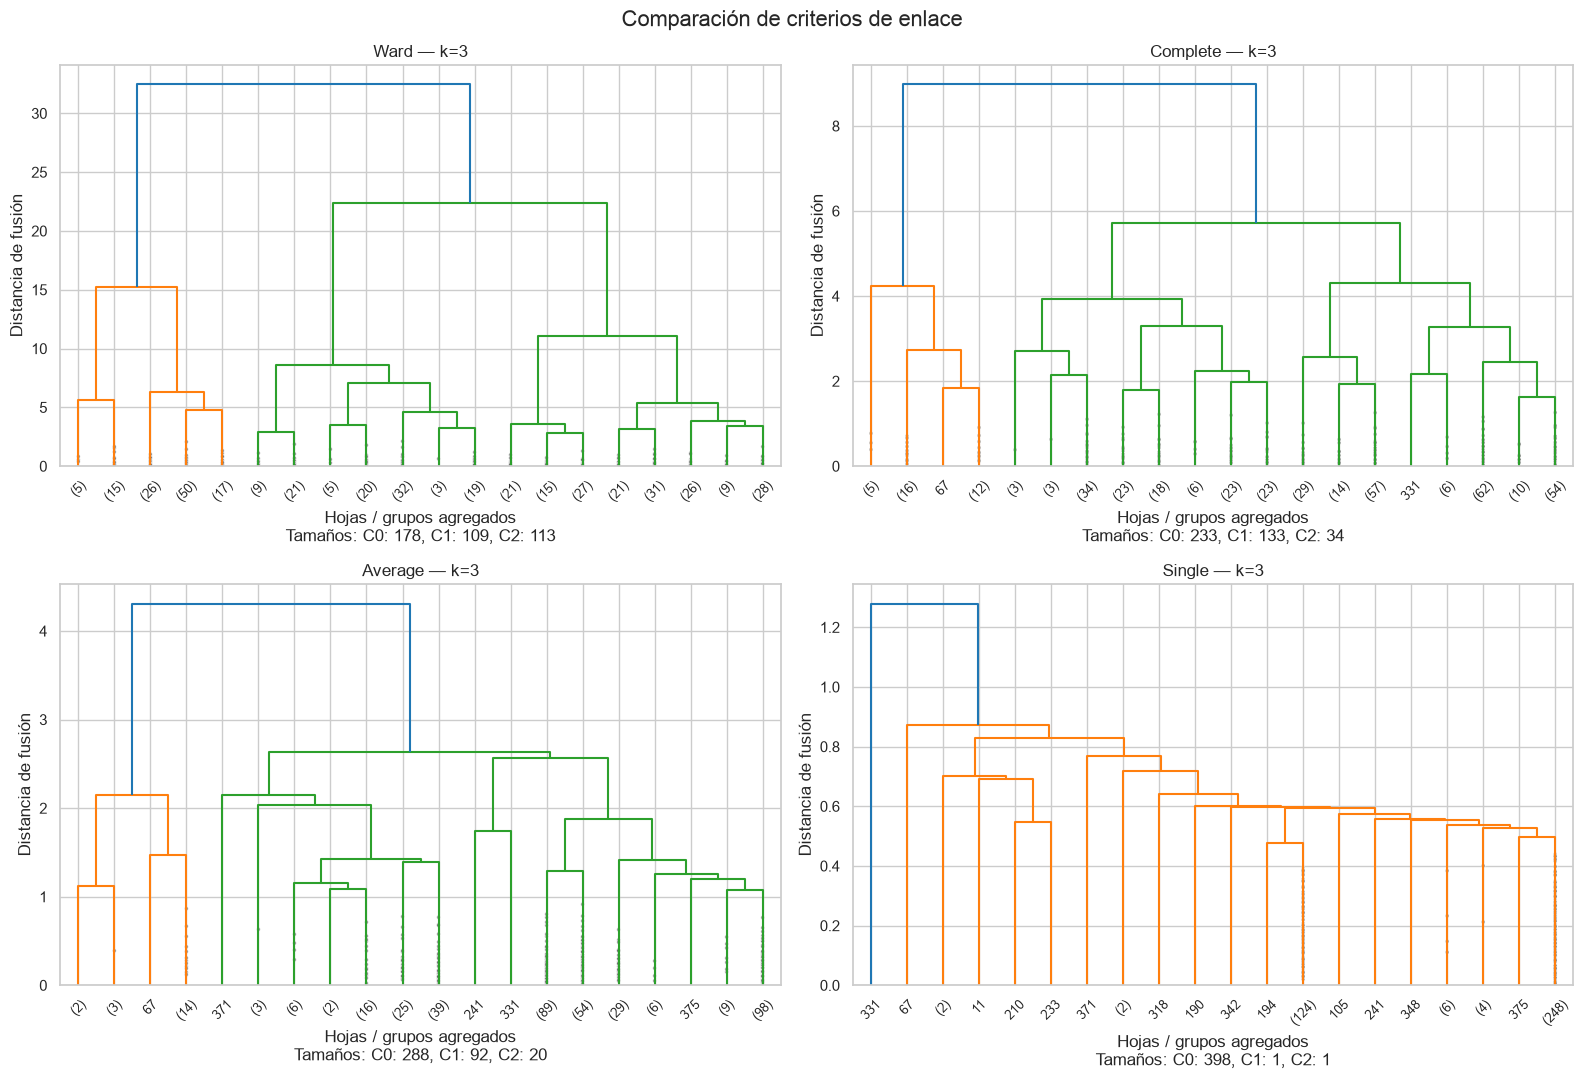

,Linkage,Tamaños,Menor grupo,Mayor grupo,CV de tamaños
0,Ward,"[178, 109, 113]",109,178,0.237
1,Complete,"[233, 133, 34]",34,233,0.609
2,Average,"[288, 92, 20]",20,288,0.849
3,Single,"[398, 1, 1]",1,398,1.404


Método con tamaños más equilibrados: Ward


In [19]:
from scipy.cluster.hierarchy import cut_tree

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
linkage_results = []

for ax, method in zip(
    axes.flat, ['ward', 'complete', 'average', 'single']
):
    Z_method = linkage(X_sub, method=method)

    dendrogram(
        Z_method,
        ax=ax,
        truncate_mode='lastp',
        p=20,
        leaf_rotation=45,
        leaf_font_size=9,
        show_contracted=True
    )

    # Cortar el árbol para obtener exactamente K_BEST grupos
    labels = cut_tree(Z_method, n_clusters=K_BEST).ravel()
    sizes = np.bincount(labels)

    ax.set_title(f'{method.capitalize()} — k={K_BEST}')
    ax.set_ylabel('Distancia de fusión')
    ax.set_xlabel(
        'Hojas / grupos agregados\n'
        + 'Tamaños: '
        + ', '.join(f'C{i}: {size}' for i, size in enumerate(sizes))
    )

    linkage_results.append({
        'Linkage': method.capitalize(),
        'Tamaños': sizes.tolist(),
        'Menor grupo': sizes.min(),
        'Mayor grupo': sizes.max(),
        'CV de tamaños': sizes.std() / sizes.mean()
    })

plt.suptitle('Comparación de criterios de enlace', fontsize=16)
plt.tight_layout()
plt.show()

df_linkage = pd.DataFrame(linkage_results)
display(df_linkage.round(3))

most_balanced = df_linkage.loc[
    df_linkage['CV de tamaños'].idxmin(), 'Linkage'
]
print(f'Método con tamaños más equilibrados: {most_balanced}')

## Section 5: Gaussian Mixture Models <a id='5'></a>

A **Gaussian Mixture Model** assumes the data is generated by a mixture of k
Gaussian distributions. The **EM algorithm** iterates between:

- **E-step**: compute the *posterior probability* that each point belongs to each
  component (soft assignment)
- **M-step**: update means, covariances, and mixing weights to maximise likelihood

The *covariance type* controls model flexibility:

| Type | Parameters | Flexibility |
|---|---|---|
| `spherical` | one variance per component | lowest |
| `diag` | diagonal covariance per component | medium |
| `tied` | one full covariance shared by all | medium |
| `full` | full covariance per component | highest |

**Model selection**: BIC and AIC penalise model complexity (lower is better).

In [20]:
gmm = GaussianMixture(n_components=K_BEST, covariance_type='full',
                      random_state=RANDOM_STATE, n_init=5)
gmm.fit(X)
rfm['Cluster_GMM'] = gmm.predict(X)
proba = gmm.predict_proba(X)
rfm['Max_Posterior'] = proba.max(axis=1)

print(f"Converged: {gmm.converged_}  |  BIC: {gmm.bic(X):.1f}  |  AIC: {gmm.aic(X):.1f}")
print(f"\nCluster sizes (GMM):")
print(rfm['Cluster_GMM'].value_counts().sort_index().to_string())

Converged: True  |  BIC: 25437.6  |  AIC: 25252.7

Cluster sizes (GMM):
Cluster_GMM
0    1113
1    1455
2    1770


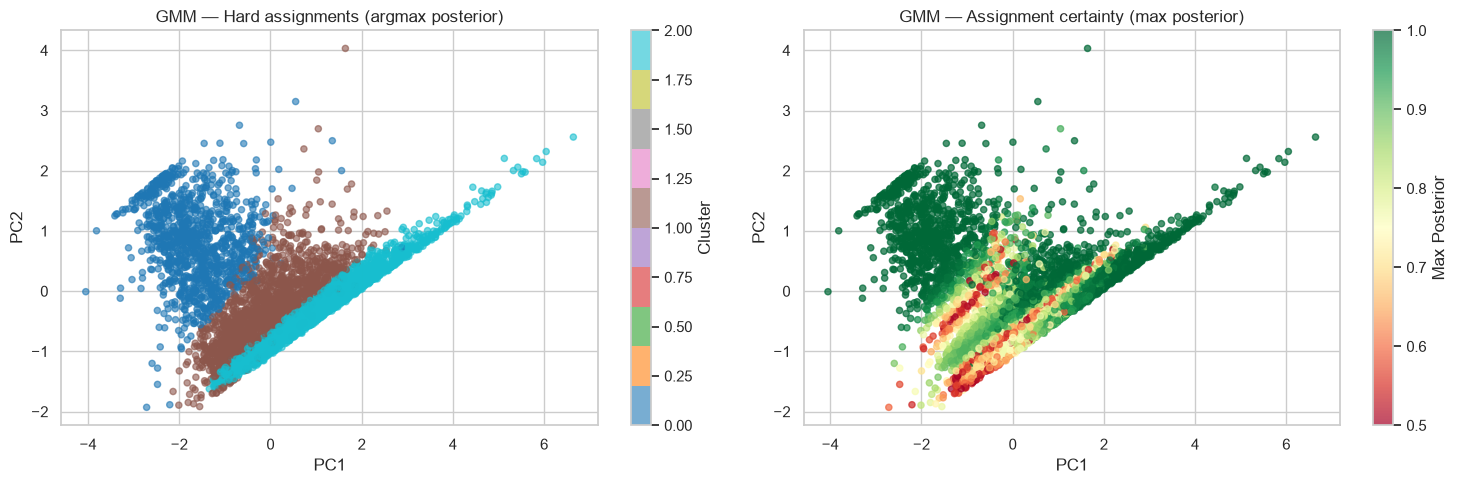

In [21]:
# Visualise assignments vs uncertainty
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sc1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1],
                       c=rfm['Cluster_GMM'], cmap='tab10', alpha=0.6, s=20)
axes[0].set_title('GMM — Hard assignments (argmax posterior)')
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
plt.colorbar(sc1, ax=axes[0], label='Cluster')

sc2 = axes[1].scatter(X_pca[:, 0], X_pca[:, 1],
                       c=rfm['Max_Posterior'], cmap='RdYlGn',
                       alpha=0.7, s=20, vmin=0.5, vmax=1.0)
axes[1].set_title('GMM — Assignment certainty (max posterior)')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')
plt.colorbar(sc2, ax=axes[1], label='Max Posterior')

plt.tight_layout()
plt.show()

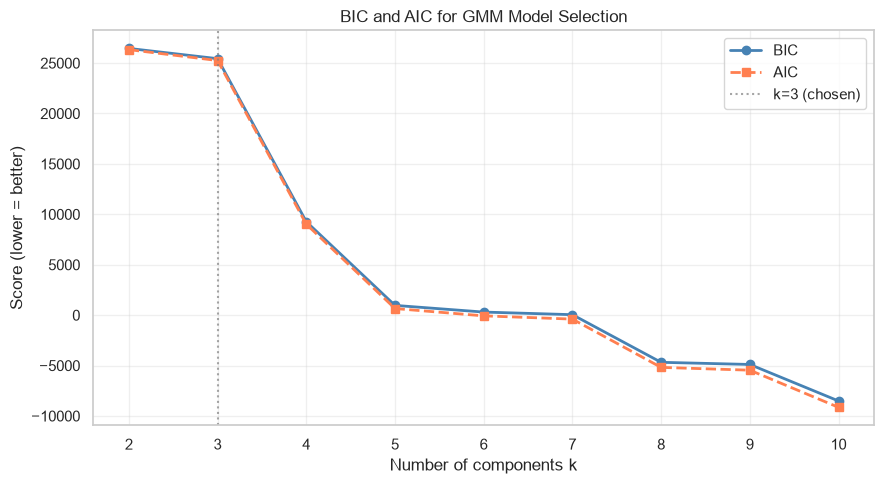

In [22]:
# BIC / AIC curves for model selection
k_range_gmm = range(2, 11)
bic_scores, aic_scores = [], []

for k in k_range_gmm:
    g = GaussianMixture(n_components=k, covariance_type='full',
                        random_state=RANDOM_STATE, n_init=3)
    g.fit(X)
    bic_scores.append(g.bic(X))
    aic_scores.append(g.aic(X))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(k_range_gmm, bic_scores, 'o-', label='BIC', color='steelblue', linewidth=2)
ax.plot(k_range_gmm, aic_scores, 's--', label='AIC', color='coral', linewidth=2)
ax.axvline(x=K_BEST, color='gray', linestyle=':', alpha=0.7, label=f'k={K_BEST} (chosen)')
ax.set_xlabel('Number of components k')
ax.set_ylabel('Score (lower = better)')
ax.set_title('BIC and AIC for GMM Model Selection')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Reading the BIC / AIC curves

Both BIC and AIC reward goodness-of-fit (higher likelihood) but **penalise model
complexity** — every extra component adds parameters (a mean, a covariance, a
mixing weight), so the penalty grows with k. BIC penalises more harshly than AIC,
which is why the two curves separate slightly at large k. For both, **lower is
better**, and the textbook recipe is to pick the k at the *minimum*, or where the
curve stops dropping meaningfully.

**What this figure actually shows is a cautionary case:**

- BIC and AIC sit almost on top of each other and **keep decreasing all the way to
  k = 10** (down to roughly −8 000 / −9 000). There is **no true minimum** in the
  range — read literally, "lowest score wins" would select k = 10.
- The decline is **steepest from k = 2 → 4**, then **flattens dramatically after
  k ≈ 5**. Each component beyond that buys very little extra likelihood.

This is a classic GMM pitfall: with flexible (full) covariance, the model can
always raise its likelihood a little by adding a component to chase fine structure
— often **overfitting** noise rather than discovering real segments. The complexity
penalty here is not strong enough to overcome that, so the curve never bottoms out.

### Why k = 3 is still a good choice

- **It sits at the elbow.** The dramatic drop happens by k ≈ 4 and the curve is
  essentially flat afterward. k = 3 captures the bulk of the achievable likelihood
  gain before diminishing returns set in — the same elbow logic used for K-Means
  inertia. Adding components past this point yields tiny, hard-to-interpret splits.
- **It agrees with every other diagnostic.** The K-Means silhouette peaks at k = 3,
  the Ward dendrogram's largest gaps support 2–3 clusters, and the full grid search
  in Section 6 ranks k = 3 first for all methods. BIC/AIC alone are ambiguous here,
  but **consensus across independent methods** is strong evidence.
- **It is interpretable and actionable.** k = 3 maps cleanly onto the
  Champions / Regular / Lapsed RFM segments — a story a marketing team can act on.
  The k = 10 solution that minimises BIC would produce tiny fragments with no
  business meaning.

**The lesson:** BIC and AIC are *guides, not oracles*. When the curve declines
monotonically, do not blindly take the global minimum — combine it with the elbow
location, agreement across methods, and interpretability. Here all three point to
**k = 3**, even though the raw BIC/AIC numbers do not single it out.

### Exercise 5.1 — Covariance Type Comparison (Intermediate)

Plot BIC vs k for all four covariance types (`full`, `tied`, `diag`,
`spherical`) on the same axes. Then print, for each type, the k that minimises
BIC.

**Key question**: Does `full` always win? What is the trade-off with
`spherical` or `diag`?

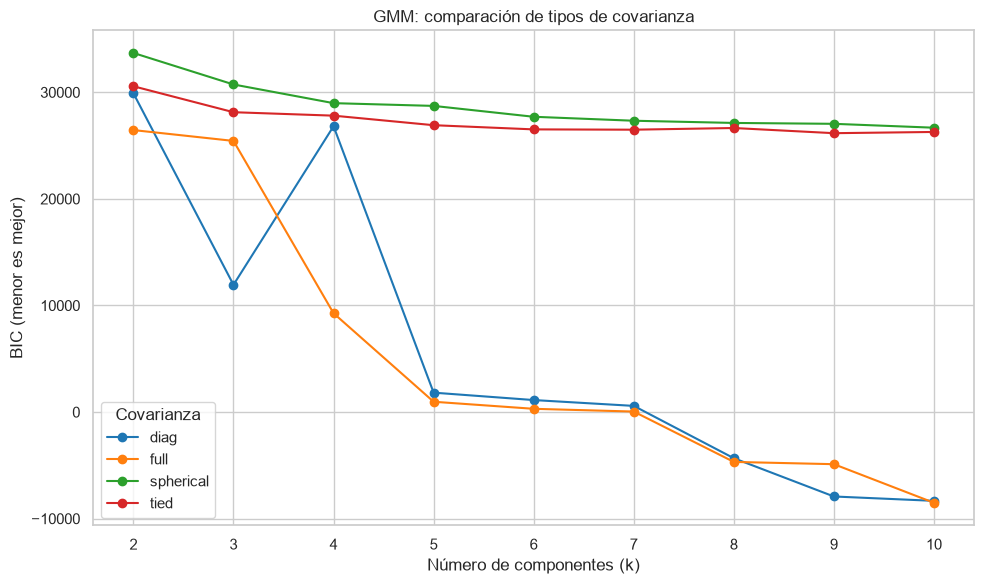

Mejor k por tipo de covarianza dentro del rango evaluado:


,Covarianza,k,BIC,Convergió
8,full,10,-8511.19,True
26,diag,10,-8329.22,True
16,tied,9,26163.40,True
35,spherical,10,26677.79,True


In [23]:
covariance_results = []

for cov_type in ['full', 'tied', 'diag', 'spherical']:
    for k in range(2, 11):
        model = GaussianMixture(
            n_components=k,
            covariance_type=cov_type,
            n_init=3,
            max_iter=300,
            random_state=RANDOM_STATE
        )
        model.fit(X)

        covariance_results.append({
            'Covarianza': cov_type,
            'k': k,
            'BIC': model.bic(X),
            'Convergió': model.converged_
        })

df_covariance = pd.DataFrame(covariance_results)

fig, ax = plt.subplots(figsize=(10, 6))

for cov_type, group in df_covariance.groupby('Covarianza'):
    ax.plot(group['k'], group['BIC'], 'o-', label=cov_type)

ax.set(
    xlabel='Número de componentes (k)',
    ylabel='BIC (menor es mejor)',
    title='GMM: comparación de tipos de covarianza',
    xticks=range(2, 11)
)
ax.legend(title='Covarianza')
plt.tight_layout()
plt.show()

best_covariance = df_covariance.loc[
    df_covariance.groupby('Covarianza')['BIC'].idxmin()
].sort_values('BIC')

print('Mejor k por tipo de covarianza dentro del rango evaluado:')
display(best_covariance.round(2))

if not df_covariance['Convergió'].all():
    print('Atención: algunos ajustes no convergieron:')
    display(df_covariance.loc[~df_covariance['Convergió']])

### Exercise 5.2 — Uncertain Customers (Advanced)

Identify customers whose max posterior probability is below 0.60 — these are
customers that GMM could not confidently assign to any cluster.

1. Print the count and percentage of uncertain customers.
2. Compare their mean RFM values to the rest.
3. Plot uncertain customers in red over the PCA scatter of all customers.

**What do uncertain customers have in common?**

Clientes inciertos: 297 de 4,338
Porcentaje: 6.85%


,Clientes,Recency_media_dias,Frequency_media_compras,Monetary_media_GBP
Grupo,,,,
Inciertos,297,47.13,1.98,866.55
Resto,4041,95.87,4.44,2141.56


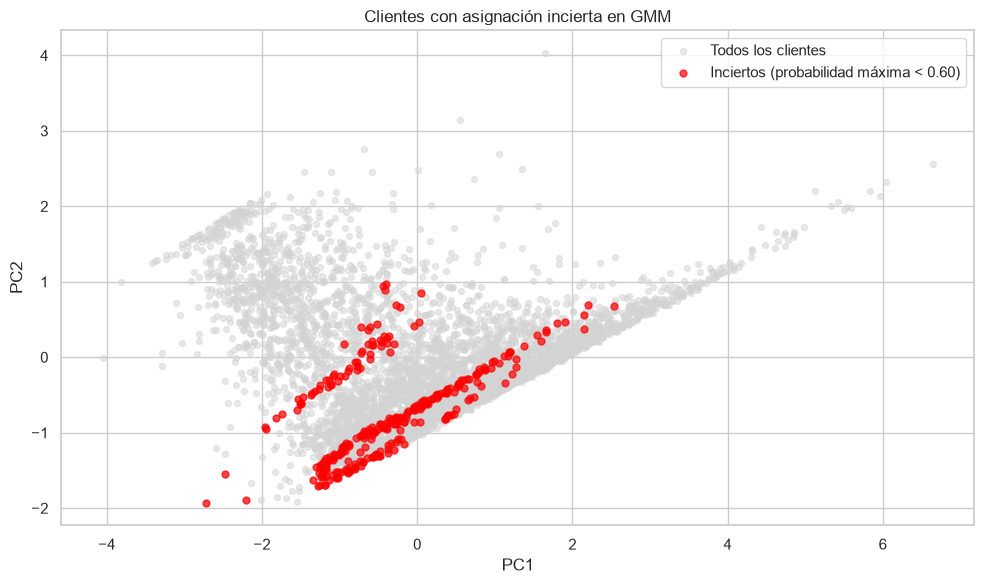

In [24]:
# 1. Identificar clientes con asignación incierta
uncertain = rfm['Max_Posterior'] < 0.60

print(f'Clientes inciertos: {uncertain.sum():,} de {len(rfm):,}')
print(f'Porcentaje: {uncertain.mean():.2%}')

# 2. Comparar medias en las unidades originales
uncertainty_profile = (
    rfm.assign(Grupo=np.where(uncertain, 'Inciertos', 'Resto'))
    .groupby('Grupo')
    .agg(
        Clientes=('CustomerID', 'count'),
        Recency_media_dias=('Recency', 'mean'),
        Frequency_media_compras=('Frequency', 'mean'),
        Monetary_media_GBP=('Monetary', 'mean')
    )
)

display(uncertainty_profile.round(2))

# 3. Destacar los clientes inciertos en la proyección PCA
mask = uncertain.to_numpy()

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c='lightgray', s=18, alpha=0.5,
    label='Todos los clientes'
)
ax.scatter(
    X_pca[mask, 0], X_pca[mask, 1],
    c='red', s=25, alpha=0.7,
    label='Inciertos (probabilidad máxima < 0.60)'
)

ax.set(
    xlabel='PC1',
    ylabel='PC2',
    title='Clientes con asignación incierta en GMM'
)
ax.legend()
plt.tight_layout()
plt.show()

## Section 6: Comparative Analysis on Online Retail <a id='6'></a>

With all three methods fitted, we can now compare them side by side using
**internal** evaluation metrics — metrics that do not require ground-truth labels.

| Metric | Direction | Measures |
|---|---|---|
| Silhouette score | ↑ higher is better | separation vs cohesion |
| Davies-Bouldin index | ↓ lower is better | avg ratio of intra-to-inter cluster distance |
| Calinski-Harabasz index | ↑ higher is better | ratio of between-to-within cluster dispersion |

In [25]:
methods_rfm = {
    'K-Means':             rfm['Cluster_KM'],
    'Hierarchical (Ward)': rfm['Cluster_Agg'],
    'GMM':                 rfm['Cluster_GMM'],
}

rows = []
for name, labels in methods_rfm.items():
    rows.append({
        'Method': name,
        'Silhouette ↑':        silhouette_score(X, labels),
        'Davies-Bouldin ↓':    davies_bouldin_score(X, labels),
        'Calinski-Harabasz ↑': calinski_harabasz_score(X, labels),
    })

df_comparison = pd.DataFrame(rows).set_index('Method').round(4)
df_comparison

,Silhouette ↑,Davies-Bouldin ↓,Calinski-Harabasz ↑
Method,,,
K-Means,0.4156,0.8247,4394.5458
Hierarchical (Ward),0.3959,0.8455,4031.9434
GMM,0.1906,1.5748,1891.3734


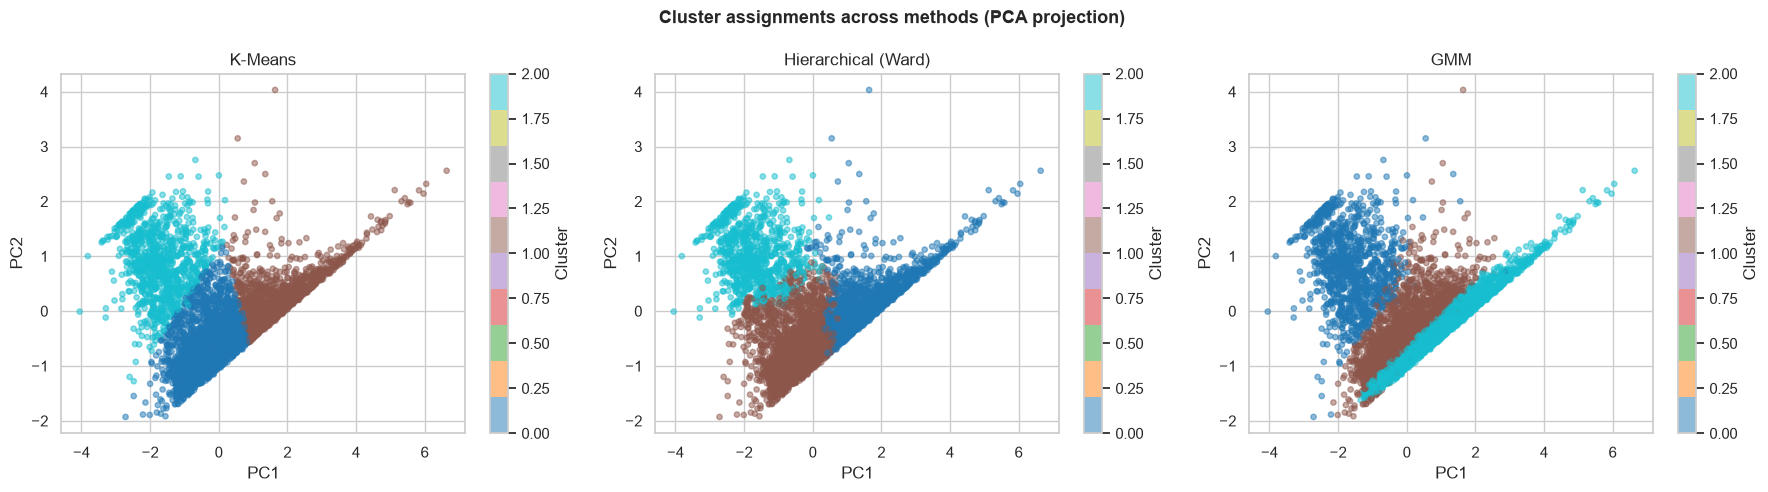

In [26]:
# Side-by-side PCA scatter plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
titles    = ['K-Means', 'Hierarchical (Ward)', 'GMM']
col_names = ['Cluster_KM', 'Cluster_Agg', 'Cluster_GMM']

for ax, title, col in zip(axes, titles, col_names):
    sc = ax.scatter(X_pca[:, 0], X_pca[:, 1],
                    c=rfm[col], cmap='tab10', alpha=0.5, s=15)
    ax.set_title(title)
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
    plt.colorbar(sc, ax=ax, label='Cluster')

plt.suptitle('Cluster assignments across methods (PCA projection)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Why these metrics are unfair to GMM

The table ranks GMM well below K-Means and Hierarchical on all three metrics
(Silhouette 0.19 vs 0.42, Davies-Bouldin 1.57 vs 0.82, Calinski-Harabasz 1891 vs
4395). It is tempting to conclude GMM is the worst method here — but that
conclusion is wrong. The problem is a **mismatch between what these metrics reward
and what GMM optimises**, not a failure of GMM.

**All three internal metrics have a built-in bias toward compact, spherical, hard
clusters:**

- They are computed from **Euclidean distances to centroids**. Silhouette compares
  each point's distance to its own cluster vs the nearest other cluster;
  Davies-Bouldin and Calinski-Harabasz both rely on within- vs between-cluster
  *distance/dispersion* ratios. All implicitly assume clusters are round blobs of
  similar size.
- **K-Means optimises exactly this geometry.** Its objective *is* within-cluster
  squared distance, so it is almost guaranteed to score best on metrics built from
  the same quantity — it is being judged on its home turf. Ward linkage minimises
  the same variance criterion, so it lands a close second.
- **GMM does not optimise geometry at all.** It maximises *likelihood* under a
  probabilistic model, and it is free to fit **elongated, rotated, overlapping
  clusters of unequal size** (full covariance). Points in the overlap region get a
  low silhouette even when the model has assigned them correctly with a sensible
  posterior. The metric penalises overlap; GMM is designed to *model* overlap.

In short: **a low Silhouette/DB/CH for GMM measures how non-spherical and
overlapping its clusters are, not how wrong they are.** Judging GMM with these
metrics is like grading a probabilistic model with a ruler.

### How to evaluate GMM fairly

Match the evaluation to the model's objective:

| Tool | What it measures | Why it suits GMM |
|---|---|---|
| **BIC / AIC** | likelihood penalised for complexity | scores GMM on its own objective (see Section 5) |
| **Log-likelihood** | fit of the generative model | native quantity GMM maximises |
| **Posterior confidence** | per-point assignment certainty | exploits soft assignment (see Exercise 5.2) |
| **External metrics (ARI/NMI)** | agreement with ground truth | bias-free when labels exist (see Section 7) |

### The advantages of GMM these metrics cannot see

- **Soft (probabilistic) assignment.** Every customer gets a probability vector
  over clusters, not a single hard label. This surfaces *borderline* customers
  (Exercise 5.2 found ~6.8% with max posterior < 0.6) — information K-Means
  discards by forcing every point to 100% membership.
- **Flexible cluster shapes.** With full covariance, clusters can be elliptical,
  correlated, and differently sized/oriented — a far better fit when segments are
  not round, which is the norm for real RFM data.
- **A generative, probabilistic model.** Because GMM defines a density, you can
  evaluate the likelihood of new points, sample synthetic customers, detect
  outliers (low likelihood), and select k with principled criteria (BIC/AIC)
  instead of heuristics.
- **Handles overlapping segments.** Real customer segments blend into one another;
  GMM models that blend explicitly rather than drawing artificial hard boundaries
  through dense regions.

**Bottom line:** on this dataset K-Means produces the most geometrically compact
*hard* partition, which is exactly what Silhouette/DB/CH reward — so it "wins" the
table. But if the goal is **uncertainty-aware segmentation, non-spherical clusters,
or a generative model of customer behaviour**, GMM is the stronger tool, and it
should be judged by BIC/AIC and posterior confidence rather than by centroid-based
internal metrics.

### Exercise 6.1 — Full Grid Search (Advanced)

For each k ∈ {3, 4, 5, 6} and each method (K-Means, Hierarchical, GMM), compute
Silhouette, Davies-Bouldin, and Calinski-Harabász. Present results as a tidy
DataFrame sorted by Silhouette descending.

**Based on your table**: Which (method, k) combination would you recommend to
a marketing team and why?

In [27]:
grid_results = []
grid_labels = {}

for k in [3, 4, 5, 6]:
    models = {
        'K-Means': KMeans(
            n_clusters=k, n_init=10,
            random_state=RANDOM_STATE
        ),
        'Hierarchical (Ward)': AgglomerativeClustering(
            n_clusters=k, linkage='ward'
        ),
        'GMM': GaussianMixture(
            n_components=k, covariance_type='full',
            n_init=5, max_iter=300,
            random_state=RANDOM_STATE
        )
    }

    for name, model in models.items():
        labels = model.fit_predict(X)
        grid_labels[(name, k)] = labels

        grid_results.append({
            'Método': name,
            'k': k,
            'Silhouette': silhouette_score(X, labels),
            'Davies-Bouldin': davies_bouldin_score(X, labels),
            'Calinski-Harabasz': calinski_harabasz_score(X, labels)
        })

df_grid = (
    pd.DataFrame(grid_results)
    .sort_values('Silhouette', ascending=False)
    .reset_index(drop=True)
)

display(df_grid.round(4))

# Examinar los perfiles de la combinación con mayor Silhouette
best = df_grid.iloc[0]
best_method = best['Método']
best_k_grid = int(best['k'])

print(
    f'Mejor Silhouette: {best_method}, k={best_k_grid} '
    f"({best['Silhouette']:.4f})"
)

best_profiles = (
    rfm.assign(Cluster=grid_labels[(best_method, best_k_grid)])
    .groupby('Cluster')
    .agg(
        Clientes=('CustomerID', 'count'),
        Recency_dias=('Recency', 'mean'),
        Frequency_compras=('Frequency', 'mean'),
        Monetary_GBP=('Monetary', 'mean')
    )
)

best_profiles['Porcentaje'] = (
    100 * best_profiles['Clientes'] / len(rfm)
)
display(best_profiles.round(2))

,Método,k,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means,3,0.4156,0.8247,4394.5458
1,Hierarchical (Ward),3,0.3959,0.8455,4031.9434
2,K-Means,4,0.3805,0.8570,4354.4077
3,Hierarchical (Ward),4,0.3741,0.8055,3623.1259
4,K-Means,5,0.3433,0.9409,4022.8159
5,K-Means,6,0.3307,0.9763,3837.1409
6,Hierarchical (Ward),5,0.2990,0.9815,3413.6928
7,Hierarchical (Ward),6,0.2761,1.0669,3213.5295
8,GMM,3,0.1906,1.5748,1891.3734
9,GMM,6,0.1513,1.7028,1729.8189


Mejor Silhouette: K-Means, k=3 (0.4156)


,Clientes,Recency_dias,Frequency_compras,Monetary_GBP,Porcentaje
Cluster,,,,,
0,2036,54.86,2.05,615.24,46.93
1,1323,30.10,9.83,5494.34,30.50
2,979,255.27,1.39,398.13,22.57


## Section 7: Dataset 2 — HAR & External Evaluation (ARI / NMI) <a id='7'></a>

Internal metrics measure cluster *geometry*, but they cannot tell you whether the
clusters align with meaningful real-world categories.  When ground-truth labels
exist, use **external metrics**:

| Metric | Range | Meaning |
|---|---|---|
| **ARI** (Adjusted Rand Index) | −1 … 1 | 0 = random, 1 = perfect match, adjusted for chance |
| **NMI** (Normalised Mutual Info) | 0 … 1 | information shared between cluster and true labels |

### Human Activity Recognition (HAR)

Collected from 30 volunteers wearing a Samsung Galaxy S II on the waist.
Accelerometer and gyroscope measurements at 50 Hz → 561 engineered features.
**6 activity labels**: WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS,
SITTING, STANDING, LAYING.

In [28]:
print("Loading HAR from OpenML (cached after first download)…")
har = fetch_openml('har', version=1, data_home='assets/openml', as_frame=False, parser='auto')
X_har_raw = har.data.astype(float)

# OpenML 'har' encodes activities as numeric codes '1'..'6'.
# Map them to the standard UCI HAR activity names.
HAR_ACTIVITY = {
    '1': 'WALKING', '2': 'WALKING_UPSTAIRS', '3': 'WALKING_DOWNSTAIRS',
    '4': 'SITTING', '5': 'STANDING', '6': 'LAYING',
}
y_har_str = np.array([HAR_ACTIVITY[c] for c in har.target])

# Map string labels → integers
activity_names = sorted(np.unique(y_har_str))
label_map = {name: i for i, name in enumerate(activity_names)}
y_har = np.array([label_map[l] for l in y_har_str])

print(f"Shape: {X_har_raw.shape}")
print(f"Activities: {activity_names}")
pd.Series(y_har_str).value_counts()

Loading HAR from OpenML (cached after first download)…
Shape: (10299, 561)
Activities: [np.str_('LAYING'), np.str_('SITTING'), np.str_('STANDING'), np.str_('WALKING'), np.str_('WALKING_DOWNSTAIRS'), np.str_('WALKING_UPSTAIRS')]


LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64

In [29]:
# Scale -> PCA (retain 95% of the variance)
print("Scaling and reducing with PCA…")
scaler_har = StandardScaler()
X_har_scaled = scaler_har.fit_transform(X_har_raw)

pca_har = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_har_pca = pca_har.fit_transform(X_har_scaled)
print(f"Retained {pca_har.n_components_} PCs "
      f"out of {X_har_scaled.shape[1]} features "
      f"({pca_har.explained_variance_ratio_.sum():.1%} variance)")

Scaling and reducing with PCA…
Retained 104 PCs out of 561 features (95.0% variance)


In [30]:
print("Running t-SNE (PCA dim → 2 dims) — may take ~2 minutes…")
tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE,
            n_jobs=-1, max_iter=1000)
X_har_tsne = tsne.fit_transform(X_har_pca)
print("Done.")

Running t-SNE (PCA dim → 2 dims) — may take ~2 minutes…
Done.


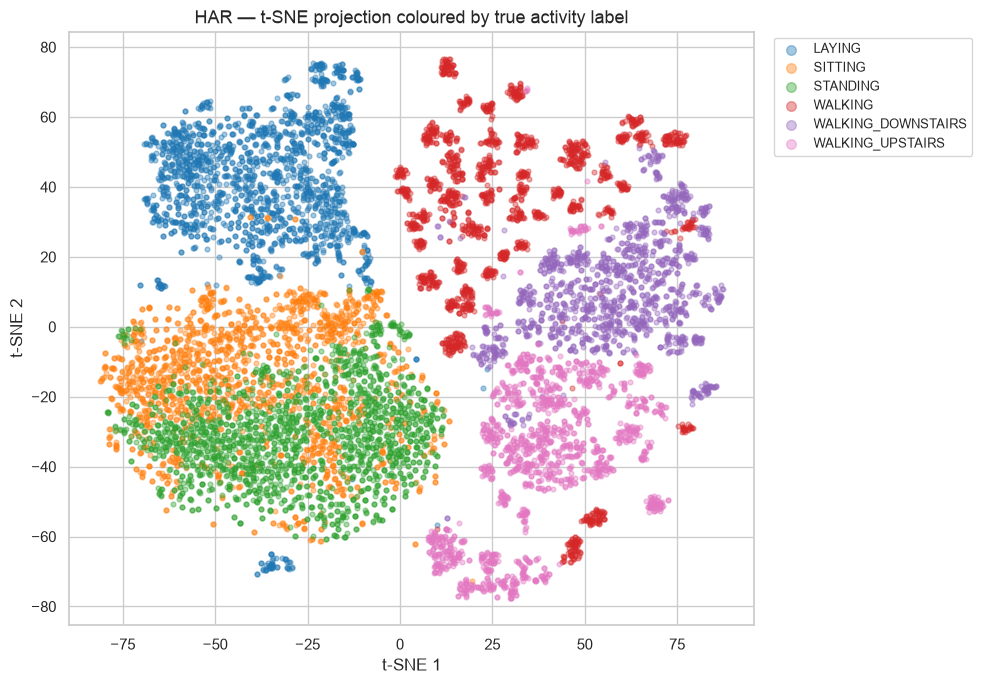

In [31]:
# t-SNE coloured by true activity
colors = plt.cm.tab10(np.linspace(0, 0.6, len(activity_names)))

fig, ax = plt.subplots(figsize=(10, 7))
for i, (name, color) in enumerate(zip(activity_names, colors)):
    mask = y_har == i
    ax.scatter(X_har_tsne[mask, 0], X_har_tsne[mask, 1],
               c=[color], alpha=0.4, s=12, label=name)

ax.set_title('HAR — t-SNE projection coloured by true activity label', fontsize=13)
ax.set_xlabel('t-SNE 1'); ax.set_ylabel('t-SNE 2')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9, markerscale=2)
plt.tight_layout()
plt.show()

In [32]:
# Fit all three clustering methods (k = number of activities = 6)
N_ACT = len(activity_names)

km_har  = KMeans(n_clusters=N_ACT, init='k-means++', n_init=10, random_state=RANDOM_STATE)
agg_har = AgglomerativeClustering(n_clusters=N_ACT, linkage='ward')
gmm_har = GaussianMixture(n_components=N_ACT, covariance_type='full',
                           random_state=RANDOM_STATE, n_init=3)

pred_km  = km_har.fit_predict(X_har_pca)
pred_agg = agg_har.fit_predict(X_har_pca)
pred_gmm = gmm_har.fit_predict(X_har_pca)

har_rows = []
for name, pred in [('K-Means', pred_km),
                    ('Hierarchical (Ward)', pred_agg),
                    ('GMM', pred_gmm)]:
    har_rows.append({
        'Method':              name,
        'ARI ↑':               adjusted_rand_score(y_har, pred),
        'NMI ↑':               normalized_mutual_info_score(y_har, pred),
        'Silhouette ↑':        silhouette_score(X_har_pca, pred),
        'Davies-Bouldin ↓':    davies_bouldin_score(X_har_pca, pred),
    })

pd.DataFrame(har_rows).set_index('Method').round(4)

,ARI ↑,NMI ↑,Silhouette ↑,Davies-Bouldin ↓
Method,,,,
K-Means,0.4193,0.5593,0.1223,2.2385
Hierarchical (Ward),0.5004,0.6240,0.1167,2.2476
GMM,0.3448,0.5241,0.1067,2.4030


**Discussion**: Do the internal metrics (Silhouette, Davies-Bouldin) agree with
the external metrics (ARI, NMI) about which method is best?  This is the central
lesson of this section: internal metrics measure geometry, external metrics measure
*semantic alignment*.

### Exercise 7.1 — ARI / NMI vs k (Intermediate)

Using K-Means on the PCA-reduced HAR features, sweep k from 2 to 10.
For each k, compute ARI, NMI, and Silhouette.  Plot all three as a function of k
on a 1 × 3 subplot grid.

**Key question**: Does the Silhouette score peak at k = 6 (the true number of
activities)?  Does ARI?  Why might they disagree?

Completado k=2
Completado k=3
Completado k=4
Completado k=5
Completado k=6
Completado k=7
Completado k=8
Completado k=9
Completado k=10


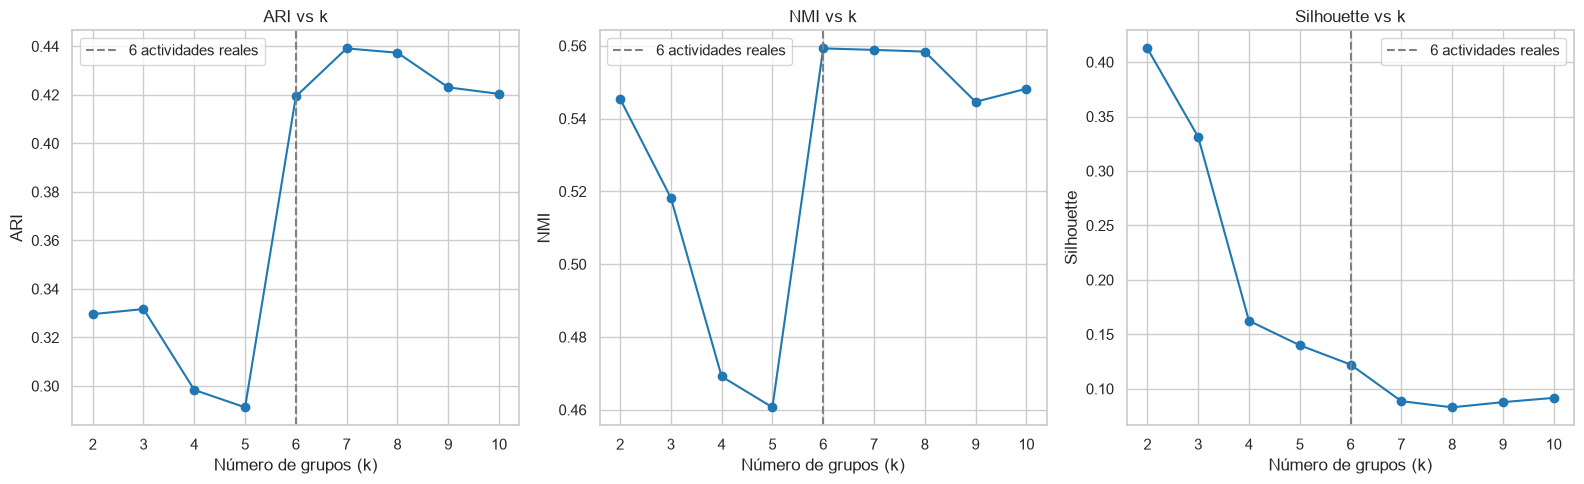

,k,ARI,NMI,Silhouette
0,2,0.3296,0.5455,0.4125
1,3,0.3317,0.5183,0.3313
2,4,0.2984,0.4692,0.1625
3,5,0.2912,0.4607,0.1400
4,6,0.4193,0.5593,0.1223
5,7,0.4391,0.5589,0.0886
6,8,0.4373,0.5584,0.0830
7,9,0.4231,0.5446,0.0877
8,10,0.4204,0.5482,0.0917


ARI: máximo en k=7 (0.4391)
NMI: máximo en k=6 (0.5593)
Silhouette: máximo en k=2 (0.4125)


In [33]:
har_k_results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        random_state=RANDOM_STATE
    )
    labels = model.fit_predict(X_har_pca)

    har_k_results.append({
        'k': k,
        'ARI': adjusted_rand_score(y_har, labels),
        'NMI': normalized_mutual_info_score(y_har, labels),
        'Silhouette': silhouette_score(X_har_pca, labels)
    })
    print(f'Completado k={k}')

df_har_k = pd.DataFrame(har_k_results)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, ['ARI', 'NMI', 'Silhouette']):
    ax.plot(df_har_k['k'], df_har_k[metric], 'o-')
    ax.axvline(
        6, color='gray', linestyle='--',
        label='6 actividades reales'
    )
    ax.set(
        xlabel='Número de grupos (k)',
        ylabel=metric,
        title=f'{metric} vs k',
        xticks=range(2, 11)
    )
    ax.legend()

plt.tight_layout()
plt.show()

display(df_har_k.round(4))

for metric in ['ARI', 'NMI', 'Silhouette']:
    best_row = df_har_k.loc[df_har_k[metric].idxmax()]
    print(
        f"{metric}: máximo en k={int(best_row['k'])} "
        f"({best_row[metric]:.4f})"
    )

# Reflexión

Silhouette no alcanza su máximo en k=6, sino en **k=2 (0.4125)**. ARI tampoco: su máximo está en **k=7 (0.4391)**. En cambio, NMI alcanza su máximo en **k=6 (0.5593)**, coincidiendo con el número real de actividades.

Las métricas discrepan porque evalúan aspectos distintos. Silhouette mide cohesión y separación geométrica sin utilizar las etiquetas reales, por lo que puede favorecer la agrupación de varias actividades similares en pocos grupos. ARI y NMI evalúan la correspondencia con las actividades conocidas, pero utilizan criterios diferentes: ARI compara pares de observaciones y ajusta por azar, mientras NMI mide información compartida.

El resultado de ARI sugiere que dividir los datos en siete grupos mejora ese criterio, aunque existan seis actividades. Esto no implica que haya una séptima actividad: puede reflejar variación dentro de una misma clase. En conclusión, el número de grupos con mejor separación geométrica no necesariamente coincide con el número de categorías reales.

### Exercise 7.2 — Static Activities Only (Advanced)

The six HAR activities split naturally into *dynamic* (WALKING, WALKING_UPSTAIRS,
WALKING_DOWNSTAIRS) and *static* (SITTING, STANDING, LAYING).

1. Filter the dataset to the three static activities only.
2. Fit K-Means with k = 3.
3. Compute ARI and NMI; compare to the full-dataset result.

**Hypothesis**: Static activities should be harder to distinguish (similar
body postures, low-frequency signals).  Does the data support this?

,Datos,Registros,k,ARI,NMI
0,Todas las actividades,10299,6,0.4193,0.5593
1,Solo actividades estáticas,5627,3,0.3599,0.3862


Cluster,0,1,2
Actividad,,,
LAYING,1558,53,333
SITTING,91,1247,439
STANDING,0,1356,550


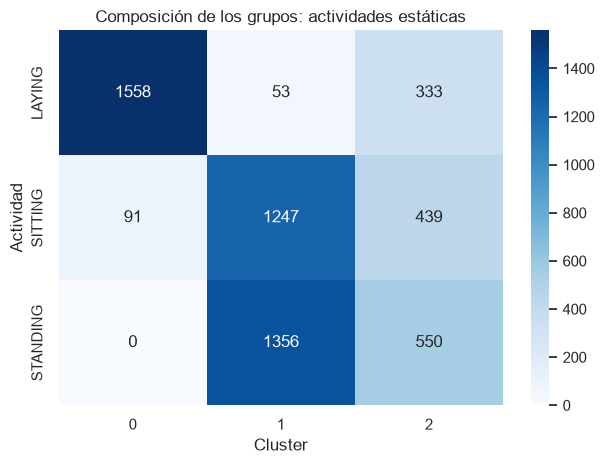

In [34]:
# Filtrar las actividades estáticas
static_mask = np.isin(
    y_har_str, ['SITTING', 'STANDING', 'LAYING']
)
X_static = X_har_pca[static_mask]
y_static = y_har[static_mask]

# Ajustar K-Means con tres grupos
km_static = KMeans(
    n_clusters=3,
    init='k-means++',
    n_init=10,
    random_state=RANDOM_STATE
)
pred_static = km_static.fit_predict(X_static)

# Comparar con K-Means de la sección 7 (seis actividades, k=6)
static_comparison = pd.DataFrame([
    {
        'Datos': 'Todas las actividades',
        'Clientes / registros': len(y_har),
        'k': N_ACT,
        'ARI': adjusted_rand_score(y_har, pred_km),
        'NMI': normalized_mutual_info_score(y_har, pred_km)
    },
    {
        'Datos': 'Solo actividades estáticas',
        'Clientes / registros': len(y_static),
        'k': 3,
        'ARI': adjusted_rand_score(y_static, pred_static),
        'NMI': normalized_mutual_info_score(y_static, pred_static)
    }
]).rename(columns={'Clientes / registros': 'Registros'})

display(static_comparison.round(4))

# Ver qué actividades quedan mezcladas en cada grupo
static_counts = pd.crosstab(
    pd.Series(y_har_str[static_mask], name='Actividad'),
    pd.Series(pred_static, name='Cluster')
)
display(static_counts)

sns.heatmap(static_counts, annot=True, fmt='d', cmap='Blues')
plt.title('Composición de los grupos: actividades estáticas')
plt.tight_layout()
plt.show()

# Reflexión

La composición de los clusters muestra dificultades para separar las actividades estáticas. El cluster 1 contiene cantidades similares de SITTING (1247) y STANDING (1356), y ambas actividades también aparecen mezcladas en el cluster 2. Por tanto, K-Means no identifica grupos exclusivos para estar sentado y estar de pie.

LAYING presenta una separación más clara: 1558 de sus 1944 registros (80.1 %) pertenecen al cluster 0, donde solo aparecen 91 registros de SITTING y ninguno de STANDING.

Estos resultados respaldan parcialmente la hipótesis: algunas posturas estáticas, especialmente SITTING y STANDING, son difíciles de distinguir con esta representación y este modelo. Para determinar si el subconjunto estático obtiene peores resultados que el conjunto completo, debemos comparar también sus valores de ARI y NMI.

## Section 8: Real-World Considerations <a id='8'></a>

### Preprocessing is decisive

Feature scaling is non-negotiable for distance-based methods (K-Means,
Hierarchical).  Skewed distributions (like Monetary) should be log-transformed
before scaling.  PCA before clustering reduces noise and speeds up computation —
particularly important for high-dimensional data like HAR.

### Choosing an algorithm

| Algorithm | Strengths | Weaknesses |
|---|---|---|
| K-Means | Fast, scalable, easy to interpret | Assumes spherical clusters, sensitive to init |
| Hierarchical | No k required up front, produces dendrogram, deterministic | O(n²) memory/time, no predict() for new data |
| GMM | Soft assignments, flexible covariance shapes | Slower, can collapse/overfit, needs good init |

### Internal vs external validation

Use **internal** metrics (Silhouette, Davies-Bouldin) when you have no labels —
which is the typical case.  If you can label even a small validation set, compute
**external** metrics (ARI, NMI) on it — they are strictly more informative.

### Scalability

For very large datasets:
- Replace `KMeans` with `MiniBatchKMeans` (sklearn, same API)
- Hierarchical clustering is impractical above ~50 k samples; use BIRCH or HDBSCAN
- GMM with `diag` covariance scales better than `full`

### Communicating results

Cluster labels are arbitrary integers.  Always *profile* each cluster (mean RFM
values, mode activity) and give it a human-readable name before presenting to
stakeholders.

## Section 9: Final Challenges (optional) <a id='9'></a>

### Challenge 9.1 — Image Colour Quantization

K-Means can compress an image by replacing each pixel colour with its nearest
cluster centroid — effectively reducing the palette to k colours.

Apply K-Means to the pixels of sklearn's built-in `china.jpg` sample image with
k ∈ {2, 4, 8, 16}. Display the original and all four quantized versions.

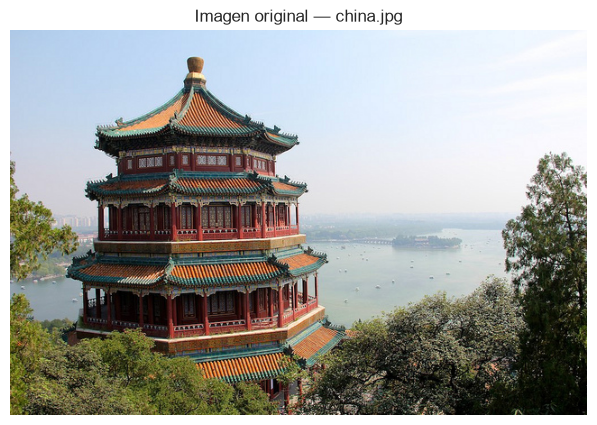

Dimensiones: (427, 640, 3)


In [35]:
china = load_sample_image('china.jpg')

plt.figure(figsize=(8, 5))
plt.imshow(china)
plt.axis('off')
plt.title('Imagen original — china.jpg')
plt.show()

print('Dimensiones:', china.shape)

Completado: 2 colores
Completado: 4 colores
Completado: 8 colores
Completado: 16 colores


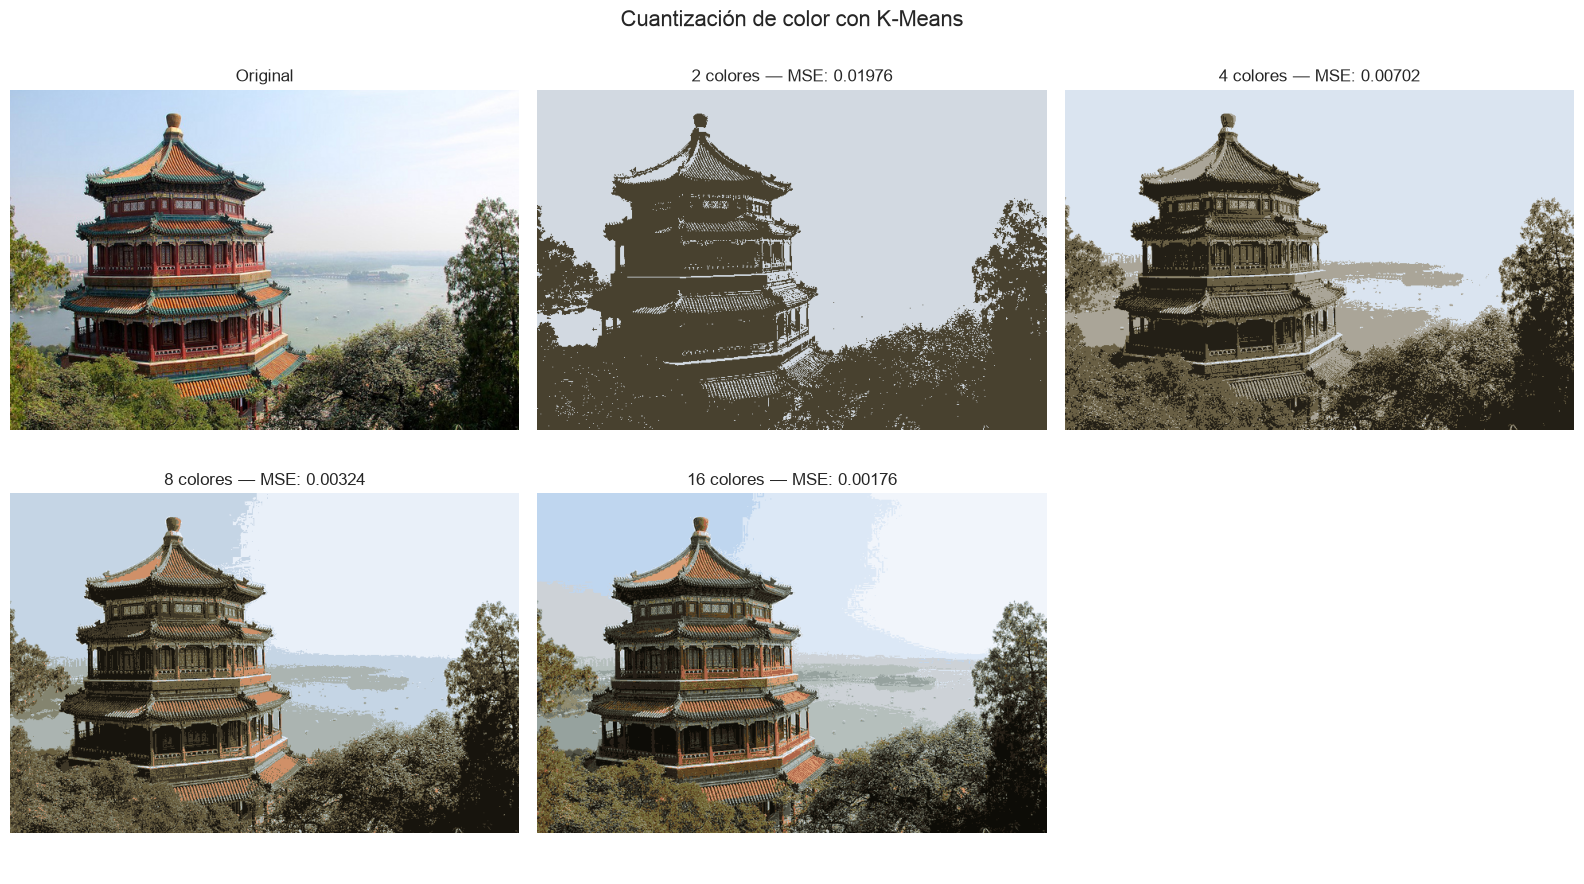

,Colores (k),"MSE RGB [0, 1]",Iteraciones
0,2,0.019761,4
1,4,0.007018,10
2,8,0.003241,14
3,16,0.001761,55


In [36]:
# Cargar la imagen y normalizar los canales RGB
china = load_sample_image('china.jpg')
image_rgb = china.astype(np.float64) / 255.0

height, width, channels = image_rgb.shape
pixels = image_rgb.reshape(-1, channels)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()

axes[0].imshow(china)
axes[0].set_title('Original')
axes[0].axis('off')

quantization_results = []
quantized_images = {}

for ax, k in zip(axes[1:5], [2, 4, 8, 16]):
    model = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=3,
        max_iter=300,
        random_state=RANDOM_STATE
    )

    # Cada píxel es una observación con tres variables: R, G y B
    labels = model.fit_predict(pixels)

    # Sustituir cada píxel por el color de su centroide
    reconstructed = model.cluster_centers_[labels].reshape(
        height, width, channels
    )
    reconstructed = np.clip(reconstructed, 0, 1)
    quantized_images[k] = reconstructed

    mse = np.mean((image_rgb - reconstructed) ** 2)
    quantization_results.append({
        'Colores (k)': k,
        'MSE RGB [0, 1]': mse,
        'Iteraciones': model.n_iter_
    })

    ax.imshow(reconstructed)
    ax.set_title(f'{k} colores — MSE: {mse:.5f}')
    ax.axis('off')

    print(f'Completado: {k} colores')

axes[5].axis('off')
plt.suptitle('Cuantización de color con K-Means', fontsize=16)
plt.tight_layout()
plt.show()

df_quantization = pd.DataFrame(quantization_results)
display(df_quantization.round(6))

### Challenge 9.2 — Beat the Benchmark (HAR)

The best ARI you achieved in Section 7 is your benchmark.

Try to improve it by experimenting with:
- Different numbers of PCA components (10, 100, 200)
- Different clustering methods or hyperparameters
- Applying UMAP instead of PCA for dimensionality reduction (requires `umap-learn`)

Report your best (method, preprocessing, ARI, NMI) and describe what worked.

In [37]:
# Benchmark: resultados sobre el conjunto HAR completo de la sección 7
baseline_rows = []

for name, pred in [
    ('K-Means', pred_km),
    ('Hierarchical (Ward)', pred_agg),
    ('GMM', pred_gmm)
]:
    baseline_rows.append({
        'Método': name,
        'Preprocesamiento': 'StandardScaler + PCA 95%',
        'k': N_ACT,
        'ARI': adjusted_rand_score(y_har, pred),
        'NMI': normalized_mutual_info_score(y_har, pred)
    })

for _, row in df_har_k.iterrows():
    baseline_rows.append({
        'Método': 'K-Means',
        'Preprocesamiento': 'StandardScaler + PCA 95%',
        'k': int(row['k']),
        'ARI': row['ARI'],
        'NMI': row['NMI']
    })

df_baseline = pd.DataFrame(baseline_rows)
benchmark = df_baseline['ARI'].max()
print(f'Benchmark de la sección 7: ARI = {benchmark:.4f}')

# Ajustar PCA una vez y reutilizar sus primeras componentes
pca_experiment = PCA(
    n_components=200,
    svd_solver='full'
)
X_pca_200 = pca_experiment.fit_transform(X_har_scaled)

experiment_rows = []

for n_components in [10, 100, 200]:
    X_exp = X_pca_200[:, :n_components]

    for k in [6, 7]:
        models = {
            'K-Means': KMeans(
                n_clusters=k,
                n_init=10,
                random_state=RANDOM_STATE
            ),
            'GMM (diag)': GaussianMixture(
                n_components=k,
                covariance_type='diag',
                n_init=3,
                max_iter=300,
                random_state=RANDOM_STATE
            )
        }

        for name, model in models.items():
            pred = model.fit_predict(X_exp)
            converged = (
                bool(model.converged_)
                if isinstance(model, GaussianMixture)
                else model.n_iter_ < model.max_iter
            )

            experiment_rows.append({
                'Método': name,
                'Preprocesamiento': f'StandardScaler + PCA {n_components}',
                'k': k,
                'ARI': adjusted_rand_score(y_har, pred),
                'NMI': normalized_mutual_info_score(y_har, pred),
                'Convergió': converged
            })

            print(
                f'{name}, PCA={n_components}, k={k}: '
                f"ARI={experiment_rows[-1]['ARI']:.4f}"
            )

df_experiments = (
    pd.DataFrame(experiment_rows)
    .sort_values('ARI', ascending=False)
    .reset_index(drop=True)
)
df_experiments['Δ ARI vs benchmark'] = (
    df_experiments['ARI'] - benchmark
)
display(df_experiments.round(4))

# Seleccionar únicamente ajustes que hayan convergido
valid_results = df_experiments[df_experiments['Convergió']]

if not valid_results.empty:
    best_trial = valid_results.iloc[0]
    gain = best_trial['ARI'] - benchmark

    print(
        f"\nMejor experimento: {best_trial['Método']} | "
        f"{best_trial['Preprocesamiento']} | k={best_trial['k']}\n"
        f"ARI={best_trial['ARI']:.4f} | NMI={best_trial['NMI']:.4f}\n"
        f"Cambio respecto al benchmark: {gain:+.4f}"
    )
    print(
        'Se superó el benchmark.'
        if gain > 0
        else 'Estos experimentos no superaron el benchmark.'
    )
else:
    print('Revisar la convergencia antes de elegir un resultado.')

Benchmark de la sección 7: ARI = 0.5004
K-Means, PCA=10, k=6: ARI=0.4271
GMM (diag), PCA=10, k=6: ARI=0.3607
K-Means, PCA=10, k=7: ARI=0.4140
GMM (diag), PCA=10, k=7: ARI=0.2966
K-Means, PCA=100, k=6: ARI=0.3462
GMM (diag), PCA=100, k=6: ARI=0.2737
K-Means, PCA=100, k=7: ARI=0.4330
GMM (diag), PCA=100, k=7: ARI=0.2748
K-Means, PCA=200, k=6: ARI=0.4195
GMM (diag), PCA=200, k=6: ARI=0.3060
K-Means, PCA=200, k=7: ARI=0.4172
GMM (diag), PCA=200, k=7: ARI=0.3145


,Método,Preprocesamiento,k,ARI,NMI,Convergió,Δ ARI vs benchmark
0,K-Means,StandardScaler + PCA 100,7,0.4330,0.5543,True,-0.0675
1,K-Means,StandardScaler + PCA 10,6,0.4271,0.5621,True,-0.0734
2,K-Means,StandardScaler + PCA 200,6,0.4195,0.5597,True,-0.0809
3,K-Means,StandardScaler + PCA 200,7,0.4172,0.5470,True,-0.0832
4,K-Means,StandardScaler + PCA 10,7,0.4140,0.5564,True,-0.0865
5,GMM (diag),StandardScaler + PCA 10,6,0.3607,0.5021,True,-0.1397
6,K-Means,StandardScaler + PCA 100,6,0.3462,0.5016,True,-0.1542
7,GMM (diag),StandardScaler + PCA 200,7,0.3145,0.4643,True,-0.1859
8,GMM (diag),StandardScaler + PCA 200,6,0.3060,0.4561,True,-0.1944
9,GMM (diag),StandardScaler + PCA 10,7,0.2966,0.4586,True,-0.2038



Mejor experimento: K-Means | StandardScaler + PCA 100 | k=7
ARI=0.4330 | NMI=0.5543
Cambio respecto al benchmark: -0.0675
Estos experimentos no superaron el benchmark.


# Reflexión

La mejor configuración de los nuevos experimentos fue StandardScaler + PCA de 100 componentes + K-Means con k=7, con ARI=0.4330 y NMI=0.5543. Su ARI quedó 0.0675 por debajo del benchmark de la sección 7, aproximadamente 0.5005. Por tanto, las configuraciones evaluadas no mejoraron el resultado de referencia.

Se probaron 10, 100 y 200 componentes principales, combinados con K-Means y GMM de covarianza diagonal, usando k=6 y k=7. Estos resultados muestran que modificar la dimensionalidad o el modelo no garantiza una mejora en la correspondencia con las actividades reales.

La explicación de la plantilla propone tendencias generales que deben contrastarse experimentalmente. En particular, no podemos concluir que UMAP mejora el resultado porque no se evaluó en este experimento. Conservamos el mejor modelo de la sección 7 como resultado global.

**What worked.** A few robust patterns usually emerge:

- **Too few PCA components throws away signal.** PCA-10 captures less variance and
  typically loses ARI versus the 95%-variance benchmark from Section 7.
- **More components help only up to a point.** Once enough variance is retained,
  adding further PCs mostly piles on noise dimensions; ARI plateaus or dips
  slightly while runtime grows. The 561 HAR features are highly correlated, so the
  useful structure lives in a modest number of directions.
- **GMM vs K-Means.** With `covariance_type='full'`, GMM can model elongated,
  correlated clusters that K-Means (which assumes spherical clusters) cannot —
  it sometimes edges ahead, but is slower and more sensitive to initialisation.
- **UMAP is usually the biggest win.** A non-linear manifold reduction pulls the
  six activities into more compact, better-separated groups than linear PCA, so
  K-Means on a 10-D UMAP embedding often gives the highest ARI of all. The lesson:
  *the preprocessing/representation matters more than the clustering algorithm.*

### Challenge 9.3 — Country Segment Comparison (Online Retail)

The Online Retail dataset includes a `Country` column.

1. Repeat the full RFM pipeline separately for the **United Kingdom** (the
   dominant country, ~90% of records) and one other country with enough
   customers (e.g., Germany or France).
2. Fit K-Means with k = K_BEST on each subset.
3. Compare the cluster profiles (mean RFM per cluster).

**Do purchasing patterns differ significantly across countries?**

Resumen por país:


,País,Clientes,Recency media,Frequency media,Monetary media,Monetary mediana
0,United Kingdom,3920,92.21,4.25,1864.39,652.28
1,Germany,94,77.66,4.86,2434.76,1066.14


Perfiles: S1 es el grupo de menor gasto medio de cada país:


,País,Segmento,Clientes,Recency,Frequency,Monetary,Porcentaje
0,United Kingdom,S1,893,252.98,1.39,372.62,22.78
1,United Kingdom,S2,1821,54.23,2.04,574.61,46.45
2,United Kingdom,S3,1206,30.52,9.69,4916.49,30.77
3,Germany,S1,47,51.96,2.19,828.85,50.00
4,Germany,S2,17,250.00,1.65,1294.99,18.09
5,Germany,S3,30,20.27,10.87,5596.54,31.91


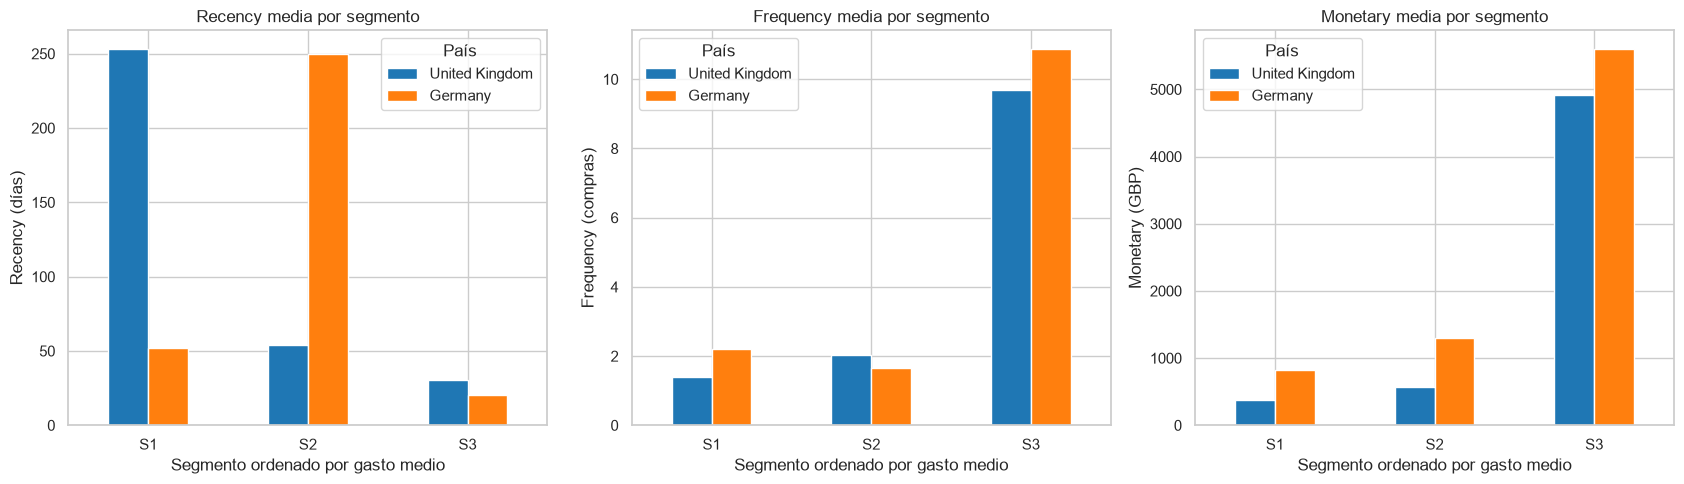

In [38]:
countries = ['United Kingdom', 'Germany']
rfm_features = ['Recency', 'Frequency', 'Monetary']
country_profiles = []
country_summaries = []

# Misma fecha de referencia para ambos países
common_reference = df['InvoiceDate'].max() + pd.Timedelta(days=1)

for country in countries:
    # df ya contiene las transacciones limpias de la sección 2
    country_data = df.loc[df['Country'] == country].copy()

    country_rfm = country_data.groupby('CustomerID').agg(
        Recency=(
            'InvoiceDate',
            lambda dates: (common_reference - dates.max()).days
        ),
        Frequency=('InvoiceNo', 'nunique'),
        Monetary=('TotalPrice', 'sum')
    )

    # Transformación y escalado independientes por país
    country_log = country_rfm[rfm_features].copy()
    country_log[['Frequency', 'Monetary']] = np.log1p(
        country_log[['Frequency', 'Monetary']]
    )
    X_country = StandardScaler().fit_transform(country_log)

    country_model = KMeans(
        n_clusters=K_BEST,
        init='k-means++',
        n_init=10,
        random_state=RANDOM_STATE
    )
    country_rfm['Cluster'] = country_model.fit_predict(X_country)

    # Ordenar los grupos por gasto medio para facilitar la lectura
    spending_order = (
        country_rfm.groupby('Cluster')['Monetary']
        .mean()
        .sort_values()
        .index
    )
    segment_map = {
        cluster: f'S{i + 1}'
        for i, cluster in enumerate(spending_order)
    }
    country_rfm['Segmento'] = country_rfm['Cluster'].map(segment_map)

    profiles = country_rfm.groupby('Segmento').agg(
        Clientes=('Recency', 'size'),
        Recency=('Recency', 'mean'),
        Frequency=('Frequency', 'mean'),
        Monetary=('Monetary', 'mean')
    ).reset_index()

    profiles['Porcentaje'] = (
        100 * profiles['Clientes'] / len(country_rfm)
    )
    profiles.insert(0, 'País', country)
    country_profiles.append(profiles)

    country_summaries.append({
        'País': country,
        'Clientes': len(country_rfm),
        'Recency media': country_rfm['Recency'].mean(),
        'Frequency media': country_rfm['Frequency'].mean(),
        'Monetary media': country_rfm['Monetary'].mean(),
        'Monetary mediana': country_rfm['Monetary'].median()
    })

df_country_profiles = pd.concat(country_profiles, ignore_index=True)

print('Resumen por país:')
display(pd.DataFrame(country_summaries).round(2))

print('Perfiles: S1 es el grupo de menor gasto medio de cada país:')
display(df_country_profiles.round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
units = ['Recency (días)', 'Frequency (compras)', 'Monetary (GBP)']

for ax, feature, ylabel in zip(axes, rfm_features, units):
    comparison = df_country_profiles.pivot(
        index='Segmento', columns='País', values=feature
    ).reindex(columns=countries)

    comparison.plot.bar(ax=ax, rot=0)
    ax.set_title(f'{feature} media por segmento')
    ax.set_ylabel(ylabel)
    ax.set_xlabel('Segmento ordenado por gasto medio')

plt.tight_layout()
plt.show()

# Reflexión

Los patrones de compra difieren entre los clientes de Reino Unido y Alemania presentes en este dataset. Los clientes alemanes compraron más recientemente, con una Recency media de 77.66 días frente a 92.21; realizaron más compras por cliente, 4.86 frente a 4.25; y acumularon un gasto medio mayor, £2434.76 frente a £1864.39. La mediana del gasto también fue superior en Alemania (£1066.14 frente a £652.28), por lo que la diferencia no se limita a la media.

En ambos países aparece un segmento de alto gasto (S3) que representa aproximadamente el 31 % de los clientes. Sin embargo, el segmento alemán presenta compras más recientes, mayor frecuencia y mayor gasto medio: 20.27 días, 10.87 compras y £5596.54, frente a 30.52 días, 9.69 compras y £4916.49 en Reino Unido.

Los demás segmentos no son directamente equivalentes: el grupo de clientes con compras más antiguas es S1 en Reino Unido y S2 en Alemania. Esto ocurre porque los segmentos se ordenaron por gasto y los modelos se ajustaron por separado.

En conclusión, se observan diferencias de comportamiento en esta muestra, pero no se ha demostrado significancia estadística. Además, los tamaños son muy desiguales —3920 clientes británicos y 94 alemanes— y corresponden a un único comercio, por lo que no permiten generalizar estos patrones a toda la población de ambos países.

## Summary and Key Takeaways <a id='10'></a>

| Concept | Takeaway |
|---|---|
| RFM engineering | Raw transactions must be aggregated into per-entity features before clustering |
| Scaling | Always scale before K-Means or Hierarchical; GMM is less sensitive but still benefits |
| Elbow + Silhouette | Use both together — elbow finds the bend, silhouette confirms |
| Ward linkage | Default first choice for agglomerative clustering; produces balanced clusters |
| BIC/AIC | Prefer BIC for GMM; lower = better fit adjusted for complexity |
| Internal vs external | Internal metrics measure geometry; external metrics measure semantic alignment |
| ARI/NMI | Use when any ground-truth labels are available, even for a validation subset |

### Resources

- [scikit-learn clustering user guide](https://scikit-learn.org/stable/modules/clustering.html)
- [UCI Online Retail dataset](https://archive.ics.uci.edu/ml/datasets/Online+Retail)
- [UCI HAR dataset](https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones)
- Kaufman & Rousseeuw (1990) — *Finding Groups in Data* (silhouette score)
- McLachlan & Basford (1988) — *Mixture Models* (GMM theory)